# Exploratory Data Analysis: Indonesian News Dataset

Analysis of 5 CSV files containing Indonesian news articles across different categories:
- Technology
- Politics
- Health
- Sport
- Education

**Schema:** `id`, `source`, `date`, `title`, `Label`, `url`

## 1. Load Datasets

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlparse
import warnings

In [2]:
files = {
    'Technology': 'data/technology.csv',
    'Politics': 'data/politic.csv',
    'Health': 'data/health.csv',
    'Sport': 'data/sport.csv',
    'Education': 'data/education.csv'
}

datasets = {}
for category, filepath in files.items():
    try:
        df = pd.read_csv(filepath, sep=';')
        datasets[category] = df
        print(f"✓ {category}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    except Exception as e:
        print(f"✗ Error loading {category}: {e}")

print(f"\nTotal datasets loaded: {len(datasets)}")

✓ Technology: 1,000 rows × 6 columns
✓ Politics: 1,000 rows × 6 columns
✓ Health: 1,000 rows × 6 columns
✓ Sport: 1,000 rows × 6 columns
✓ Education: 1,000 rows × 6 columns

Total datasets loaded: 5


## 2. Setup and Imports

In [3]:
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 100)

# ---------------------------------------------------------------
# UNIFIED GLOBAL STYLE (single source of truth for the whole notebook)
# ---------------------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 6),
    "figure.dpi": 110,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 12,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 11,
    "axes.edgecolor": "#444444",
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Fixed label mapping and colors -> a class is ALWAYS the same color
LABEL_NAMES = {0: "Non-Clickbait", 1: "Clickbait"}
LABEL_COLORS = {"Non-Clickbait": "#4C72B0", "Clickbait": "#DD8452"}
LABEL_ORDER = ["Non-Clickbait", "Clickbait"]
# Numeric-keyed label colors for cells that group by the raw 0/1 Label
LABEL_COLORS_NUM = {0: LABEL_COLORS["Non-Clickbait"], 1: LABEL_COLORS["Clickbait"]}

# Stable per-domain palette
DOMAINS = list(datasets.keys()) if "datasets" in dir() else []
DOMAIN_COLORS = dict(zip(DOMAINS, sns.color_palette("deep", len(DOMAINS)))) if DOMAINS else {}


def annotate_bars(ax, fmt="{:.0f}", fontsize=10, padding=3):
    """Write the height of each vertical bar on top of it."""
    for p in ax.patches:
        h = p.get_height()
        if not np.isfinite(h) or h == 0:
            continue
        ax.annotate(fmt.format(h),
                    (p.get_x() + p.get_width() / 2, h),
                    ha="center", va="bottom", fontsize=fontsize,
                    xytext=(0, padding), textcoords="offset points")


def annotate_barh(ax, fmt="{:.1f}%", fontsize=10, padding=3):
    """Write the width of each horizontal bar at its end."""
    for p in ax.patches:
        w = p.get_width()
        if not np.isfinite(w) or w == 0:
            continue
        ax.annotate(fmt.format(w),
                    (w, p.get_y() + p.get_height() / 2),
                    ha="left", va="center", fontsize=fontsize,
                    xytext=(padding, 0), textcoords="offset points")


def show_table(frame, title):
    """Print a titled exact-metrics table right before its paired chart."""
    print("\n" + "=" * 72 + "\n" + title + "\n" + "=" * 72)
    display(frame)


print("Setup complete - unified style, palette & helpers loaded")

Setup complete - unified style, palette & helpers loaded


## 3. Dataset Overview

In [4]:
overview_data = []
for category, df in datasets.items():
    overview_data.append({
        'Category': category,
        'Rows': f"{df.shape[0]:,}",
        'Columns': df.shape[1],
        'Memory (MB)': round(df.memory_usage(deep=True).sum() / 1024**2, 2),
        'Missing Values': df.isnull().sum().sum(),
        'Duplicate Rows': df.duplicated().sum()
    })

overview_df = pd.DataFrame(overview_data)
print("\nDataset Overview Summary:")
display(overview_df)


Dataset Overview Summary:


,Category,Rows,Columns,Memory (MB),Missing Values,Duplicate Rows
0,Technology,"1,000",6,0.42,0,0
1,Politics,"1,000",6,0.43,0,0
2,Health,"1,000",6,0.43,0,0
3,Sport,"1,000",6,0.43,0,0
4,Education,"1,000",6,0.43,0,0


### Sample Data Preview

In [5]:
for category, df in datasets.items():
    print(f"\n{category} - Sample (first 3 rows):")
    display(df.head(3))


Technology - Sample (first 3 rows):


,id,source,date,title,Label,url
0,1,Detik,03/10/2026,Pentagon Tunjuk Elon Musk Jadi Penasihat Teknologi Perang Masa Depan,0,https://inet.detik.com/cyberlife/d-8691023/pentagon-tunjuk-elon-musk-jadi-penasihat-teknologi-pe...
1,2,Detik,03/10/2026,Kuota Internet Masih Bisa Hangus? Komdigi Beri Penjelasan,0,https://inet.detik.com/telecommunication/d-8690629/kuota-internet-masih-bisa-hangus-komdigi-beri...
2,3,Detik,03/10/2026,Paket Internet Rollover Lebih Mahal? Ini Jawaban Komdigi,1,https://inet.detik.com/telecommunication/d-8690540/paket-internet-rollover-lebih-mahal-ini-jawab...



Politics - Sample (first 3 rows):


,id,source,date,title,Label,url
0,1,Detik,03/10/2026,Bamsoet Tegaskan Politik Hukum Harus Berpihak pada Kepentingan Rakyat,0,https://news.detik.com/berita/d-8691043/bamsoet-tegaskan-politik-hukum-harus-berpihak-pada-kepen...
1,2,Detik,02/10/2026,Trump Enggan Nyatakan Dukung Netanyahu Jelang Pemilu Israel,0,https://news.detik.com/internasional/d-8689661/trump-enggan-nyatakan-dukung-netanyahu-jelang-pem...
2,3,Detik,01/10/2026,Ahli KPU Nilai Gugatan Ijazah Gibran di MK Tak Tepat Usai Jadi Wapres,0,https://news.detik.com/berita/d-8688647/ahli-kpu-nilai-gugatan-ijazah-gibran-di-mk-tak-tepat-usa...



Health - Sample (first 3 rows):


,id,source,date,title,Label,url
0,1,Detik,03/10/2026,Pelihara Ayam di Rumah saat Musim Flu? Ini Saran Pakar Biar Tetap Sehat,1,https://health.detik.com/berita-detikhealth/d-8690551/pelihara-ayam-di-rumah-saat-musim-flu-ini-...
1,2,Detik,02/10/2026,Suka Makanan Tinggi Lemak? Ini 5 Cara Bantu Jaga Kesehatan Jantung,1,https://health.detik.com/berita-detikhealth/d-8690127/suka-makanan-tinggi-lemak-ini-5-cara-bantu...
2,3,Detik,02/10/2026,Sering Makan Enak? Begini Cara Jaga Kesehatan Jantung dan Kolesterol,1,https://health.detik.com/berita-detikhealth/d-8690126/sering-makan-enak-begini-cara-jaga-kesehat...



Sport - Sample (first 3 rows):


,id,source,date,title,Label,url
0,1,Detik,03/10/2026,"Tinju Gagal Sumbang Medali di Asian Games 2026, Perbati Buka Suara",1,https://sport.detik.com/sport-lain/d-8691159/tinju-gagal-sumbang-medali-di-asian-games-2026-perb...
1,2,Detik,03/10/2026,Drama Diinjak Lawan saat Sofyan/Bintang Gagal Raih Emas Asian Games,0,https://sport.detik.com/sport-lain/d-8691152/drama-diinjak-lawan-saat-sofyan-bintang-gagal-raih-...
2,3,Detik,03/10/2026,"Panjat Tebing Gagal Raih Emas, Srondeng Finis Kelima Asian Games",0,https://sport.detik.com/sport-lain/d-8691081/panjat-tebing-gagal-raih-emas-srondeng-finis-kelima...



Education - Sample (first 3 rows):


,id,source,date,title,Label,url
0,1,Detik,03/10/2026,"Guru Tak Hanya Mengajar, Mendikdasmen Tekankan Perannya sebagai Agen Peradaban",0,https://www.detik.com/edu/sekolah/d-8690423/guru-tak-hanya-mengajar-mendikdasmen-tekankan-perann...
1,2,Detik,03/10/2026,"BRIN Desain Tata Kelola Lab Sekolah, Banyak Guru Punya Keterbatasan Penerapan STEM",0,https://www.detik.com/edu/sekolah/d-8690067/brin-desain-tata-kelola-lab-sekolah-banyak-guru-puny...
2,3,Detik,03/10/2026,"Kiat Pilih Buku Bacaan yang Tepat buat Anak, Ini Kata Dosen Unila",1,https://www.detik.com/edu/edutainment/d-8690014/kiat-pilih-buku-bacaan-yang-tepat-buat-anak-ini-...


### Data Types

In [6]:
for category, df in datasets.items():
    print(f"\n{category}:")
    print(df.dtypes.to_string())
    print(f"Columns: {list(df.columns)}")


Technology:
id         int64
source    object
date      object
title     object
Label      int64
url       object
Columns: ['id', 'source', 'date', 'title', 'Label', 'url']

Politics:
id         int64
source    object
date      object
title     object
Label      int64
url       object
Columns: ['id', 'source', 'date', 'title', 'Label', 'url']

Health:
id         int64
source    object
date      object
title     object
Label      int64
url       object
Columns: ['id', 'source', 'date', 'title', 'Label', 'url']

Sport:
id         int64
source    object
date      object
title     object
Label      int64
url       object
Columns: ['id', 'source', 'date', 'title', 'Label', 'url']

Education:
id         int64
source    object
date      object
title     object
Label      int64
url       object
Columns: ['id', 'source', 'date', 'title', 'Label', 'url']


## 4. Data Quality Checks

### 4.1 Dataset Size Comparison

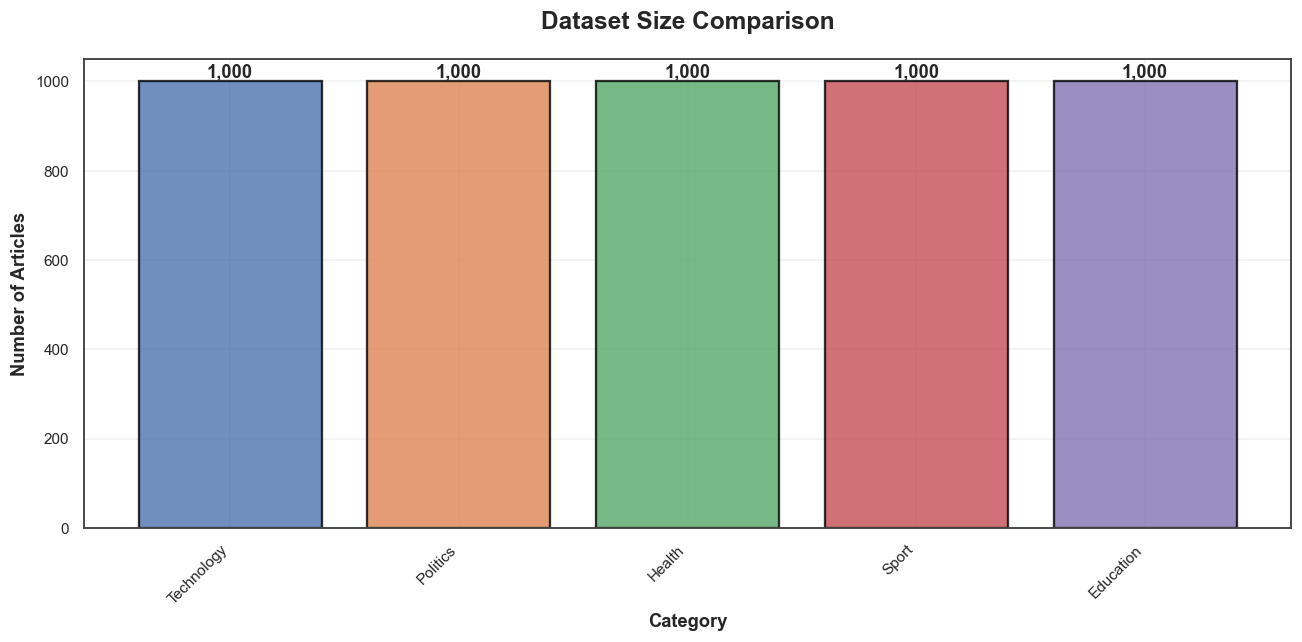


Total articles: 5,000
Average: 1000
Largest: Technology (1,000)
Smallest: Technology (1,000)


In [7]:
categories = DOMAINS
sizes = [len(datasets[c]) for c in categories]

plt.figure(figsize=(12, 6))
bars = plt.bar(
    categories,
    sizes,
    color=[DOMAIN_COLORS.get(c, "#4C72B0") for c in categories],
    edgecolor="black",
    linewidth=1.5,
    alpha=0.8,
)

plt.title("Dataset Size Comparison", fontsize=16, fontweight="bold", pad=20)
plt.xlabel("Category", fontsize=12, fontweight="bold")
plt.ylabel("Number of Articles", fontsize=12, fontweight="bold")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y", alpha=0.3)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2.0,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom",
        fontweight="bold",
    )

plt.tight_layout()
plt.show()

print(f"\nTotal articles: {sum(sizes):,}")
print(f"Average: {np.mean(sizes):.0f}")
print(f"Largest: {categories[np.argmax(sizes)]} ({max(sizes):,})")
print(f"Smallest: {categories[np.argmin(sizes)]} ({min(sizes):,})")


### 4.2 Missing Values

,Domain,Column,Missing_Count,Missing_Percentage
0,Technology,id,0,0.0
1,Technology,source,0,0.0
2,Technology,date,0,0.0
3,Technology,title,0,0.0
4,Technology,Label,0,0.0
5,Technology,url,0,0.0
6,Politics,id,0,0.0
7,Politics,source,0,0.0
8,Politics,date,0,0.0
9,Politics,title,0,0.0


,Domain,Total_Articles,Total_Missing,Completeness
0,Technology,1000,0,100.0
1,Politics,1000,0,100.0
2,Health,1000,0,100.0
3,Sport,1000,0,100.0
4,Education,1000,0,100.0


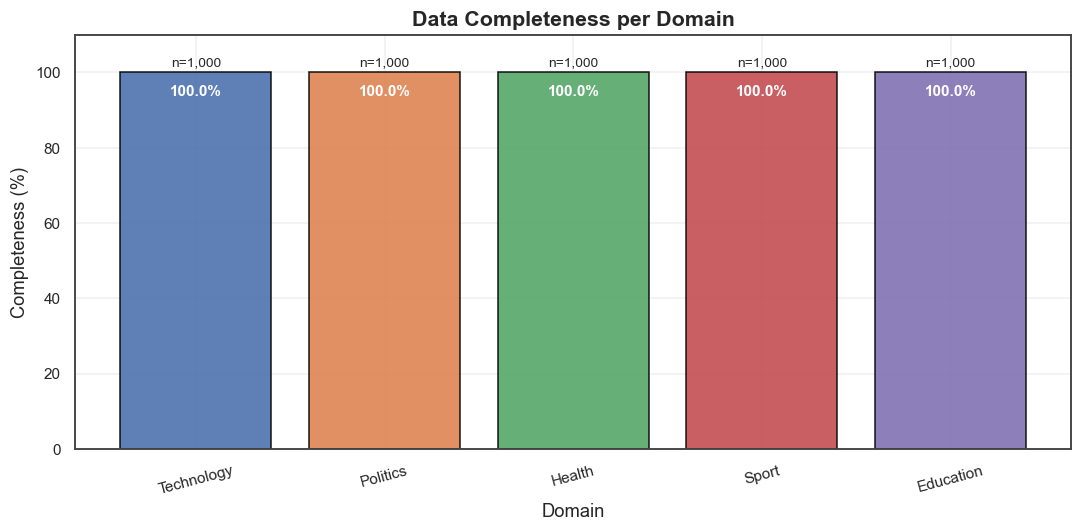

========== DATASET SUMMARY ==========
Total articles: 5,000
Total missing cells: 0
Average completeness: 100.00%


In [8]:
# =============== MISSING VALUE DATA ===============

missing_data = []
total_data = []

for category, df in datasets.items():

    total_articles = len(df)
    total_columns = len(df.columns)
    total_cells = total_articles * total_columns

    missing = df.isnull().sum()
    total_missing = missing.sum()

    total_data.append({
        "Domain": category,
        "Total_Articles": total_articles,
        "Total_Missing": total_missing,
        "Completeness": (
            (total_cells - total_missing) / total_cells * 100
            if total_cells > 0 else 0
        )
    })

    for column, count in missing.items():

        missing_data.append({
            "Domain": category,
            "Column": column,
            "Missing_Count": count,
            "Missing_Percentage": (
                count / total_articles * 100
                if total_articles > 0 else 0
            )
        })

missing_df = pd.DataFrame(missing_data)
total_df = pd.DataFrame(total_data)

display(missing_df)
display(total_df)


# =============== PLOT: DATA COMPLETENESS ===============

completeness = total_df.set_index("Domain")["Completeness"]
total_articles = total_df.set_index("Domain")["Total_Articles"]

plt.figure(figsize=(10, 5))

bars = plt.bar(
    completeness.index,
    completeness.values,
    color=[
        DOMAIN_COLORS.get(d, "#4C72B0")
        for d in completeness.index
    ],
    edgecolor="black",
    linewidth=1,
    alpha=0.9
)

for bar, domain, value in zip(
    bars, completeness.index, completeness.values
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value - 5,
        f"{value:.1f}%",
        ha="center",
        va="center",
        color="white",
        fontweight="bold",
        fontsize=10
    )

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 1,
        f"n={total_articles[domain]:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.ylabel("Completeness (%)")
plt.xlabel("Domain")
plt.title(
    "Data Completeness per Domain",
    fontsize=14,
    fontweight="bold"
)

plt.ylim(0, 110)
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.gca().set_axisbelow(True)

plt.tight_layout()
plt.show()


# =============== SUMMARY ===============

print("========== DATASET SUMMARY ==========")
print(f"Total articles: {total_df['Total_Articles'].sum():,}")
print(f"Total missing cells: {total_df['Total_Missing'].sum():,}")
print(f"Average completeness: {total_df['Completeness'].mean():.2f}%")

### 4.3 Duplicate Analysis


Duplicate Summary Across All Datasets:


,Category,Total Rows,Duplicate IDs,Duplicate Titles,Duplicate URLs,Duplicate Rows
0,Technology,1000,0,0,0,0
1,Politics,1000,0,0,0,0
2,Health,1000,0,0,0,0
3,Sport,1000,0,0,0,0
4,Education,1000,0,0,0,0


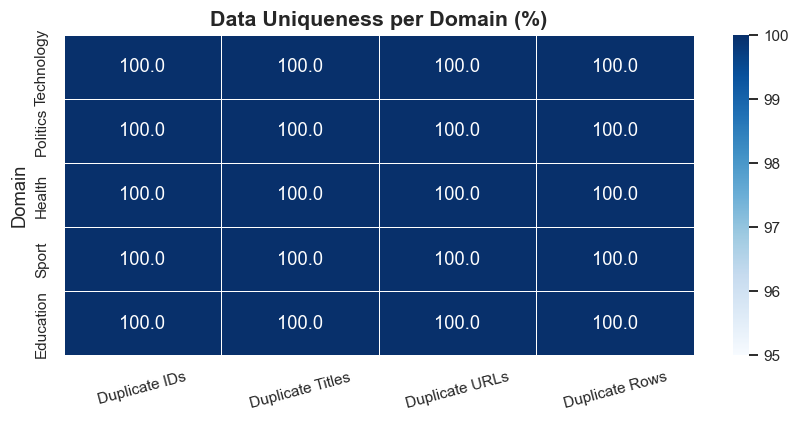

In [9]:
# ===============TABLE===============
dup_summary = []
for category, df in datasets.items():
    dup_data = {'Category': category, 'Total Rows': len(df)}

    if 'id' in df.columns:
        dup_data['Duplicate IDs'] = df['id'].duplicated().sum()
    if 'title' in df.columns:
        dup_data['Duplicate Titles'] = df['title'].duplicated().sum()
    if 'url' in df.columns:
        dup_data['Duplicate URLs'] = df['url'].duplicated().sum()

    dup_data['Duplicate Rows'] = df.duplicated().sum()
    dup_summary.append(dup_data)

dup_df = pd.DataFrame(dup_summary)
print("\nDuplicate Summary Across All Datasets:")
display(dup_df)


# ===============PLOT: DATA UNIQUENESS===============

metrics = [
    'Duplicate IDs',
    'Duplicate Titles',
    'Duplicate URLs',
    'Duplicate Rows'
]

metrics = [m for m in metrics if m in dup_df.columns]

uniqueness = dup_df[['Category'] + metrics].copy()

for metric in metrics:
    uniqueness[metric] = (
        100 - uniqueness[metric] / dup_df['Total Rows'] * 100
    )

uniqueness = uniqueness.set_index('Category')

plt.figure(figsize=(8, 4))

sns.heatmap(
    uniqueness,
    annot=True,
    fmt='.1f',
    cmap='Blues',
    vmin=95,
    vmax=100,
    linewidths=0.5,
    linecolor='white'
)

plt.title('Data Uniqueness per Domain (%)')
plt.xlabel('')
plt.ylabel('Domain')
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### 4.4 Invalid Dates

In [10]:
for category, df in datasets.items():
    if 'date' in df.columns:
        print(f"\n{category} - Date Validation:")
        df['date_parsed'] = pd.to_datetime(df['date'], format='%d/%m/%Y')
        invalid_dates = df[df['date_parsed'].isna()]

        print(f"Valid Dates: {len(df) - len(invalid_dates):,}")
        print(f"Invalid/Missing: {len(invalid_dates):,}")

        if len(invalid_dates) > 0:
            print("\nSample Invalid Dates:")
            display(invalid_dates[['id', 'date']].head())


Technology - Date Validation:
Valid Dates: 1,000
Invalid/Missing: 0

Politics - Date Validation:
Valid Dates: 1,000
Invalid/Missing: 0

Health - Date Validation:
Valid Dates: 1,000
Invalid/Missing: 0

Sport - Date Validation:
Valid Dates: 1,000
Invalid/Missing: 0

Education - Date Validation:
Valid Dates: 1,000
Invalid/Missing: 0


### 4.5 Class Imbalance Summary

,Domain,Label,Count,Percentage,Imbalance Ratio,Status
0,Technology,0,795,79.5,3.88:1,Imbalanced
1,Technology,1,205,20.5,3.88:1,Imbalanced
2,Politics,0,903,90.3,9.31:1,Imbalanced
3,Politics,1,97,9.7,9.31:1,Imbalanced
4,Health,0,438,43.8,1.28:1,Balanced
5,Health,1,562,56.2,1.28:1,Balanced
6,Sport,0,903,90.3,9.31:1,Imbalanced
7,Sport,1,97,9.7,9.31:1,Imbalanced
8,Education,0,666,66.6,1.99:1,Imbalanced
9,Education,1,334,33.4,1.99:1,Imbalanced


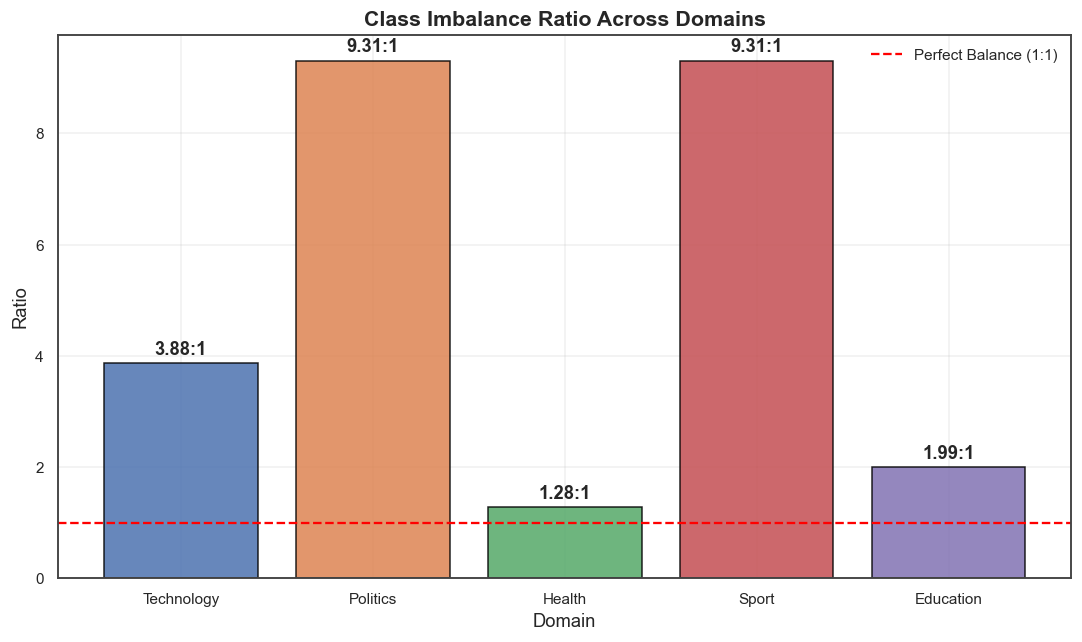

In [11]:
# =============== TABLE ===============
label_data = []

for category, df in datasets.items():
    if 'Label' not in df.columns:
        continue

    counts = df['Label'].value_counts().sort_index()
    percentages = (counts / len(df) * 100).round(2)

    if len(counts) >= 2:
        ratio = counts.max() / counts.min()
        status = 'Balanced' if ratio < 1.5 else 'Imbalanced'
    else:
        ratio = None
        status = 'Cannot determine'

    for label in counts.index:
        label_data.append({
            'Domain': category,
            'Label': label,
            'Count': counts[label],
            'Percentage': percentages[label],
            'Imbalance Ratio': ratio,
            'Status': status
        })

label_df = pd.DataFrame(label_data)

display_df = label_df.copy()
display_df['Imbalance Ratio'] = display_df['Imbalance Ratio'].apply(
    lambda x: f'{x:.2f}:1' if pd.notna(x) else None
)

display(display_df)


# =============== PLOT ===============
imbalance_plot = (
    label_df[['Domain', 'Imbalance Ratio']]
    .drop_duplicates()
    .dropna()
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    imbalance_plot['Domain'],
    imbalance_plot['Imbalance Ratio'],
    color=[
        DOMAIN_COLORS.get(d, '#4C72B0')
        for d in imbalance_plot['Domain']
    ],
    edgecolor='black',
    alpha=0.85
)

ax.axhline(
    1,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Perfect Balance (1:1)'
)

ax.bar_label(
    bars,
    labels=[f'{v:.2f}:1' for v in imbalance_plot['Imbalance Ratio']],
    padding=3,
    fontweight='bold'
)

ax.set(
    title='Class Imbalance Ratio Across Domains',
    xlabel='Domain',
    ylabel='Ratio'
)

ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### 4.6 Inter-Annotator Agreement: Fleiss' Kappa

Fleiss' Kappa mengukur kesepakatan beberapa annotator pada item yang sama setelah mengoreksi kesepakatan yang diperkirakan terjadi secara kebetulan. Rating mentah tersedia sebagai lima file CSV di `data/annotations_per_annotator/`; setiap file memuat 1.000 record berisi data dengan kolom `Jel`, `Grace`, `Nab`, dan `FINAL`. Kode di bawah menghitung Kappa gabungan dan per domain. File Politics juga memiliki 1.000 baris tambahan yang hanya berisi delimiter dan tidak memiliki data; baris tersebut dilewati, sehingga jumlah item Politics yang dianalisis tetap 1.000.

Nilai `0` berarti non-clickbait dan `1` berarti clickbait. Kolom `FINAL` dipakai untuk memeriksa apakah label akhir sama dengan majority vote; kolom ini tidak dipakai menghitung Kappa.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

annotation_dir = Path('data/annotations_per_annotator')
annotator_columns = ['Jel', 'Grace', 'Nab']
required_columns = ['id', 'title', 'FINAL', *annotator_columns, 'url']
domain_by_suffix = {
    'tech': 'Technology', 'pol': 'Politics', 'health': 'Health',
    'sport': 'Sport', 'edu': 'Education',
}

def fleiss_kappa(rating_values):
    n_items, n_raters = rating_values.shape
    category_counts = np.column_stack([
        (rating_values == category).sum(axis=1)
        for category in (0, 1)
    ])
    item_agreement = (
        np.square(category_counts).sum(axis=1) - n_raters
    ) / (n_raters * (n_raters - 1))
    observed_agreement = item_agreement.mean()
    category_proportions = category_counts.sum(axis=0) / (n_items * n_raters)
    chance_agreement = np.square(category_proportions).sum()
    if np.isclose(1 - chance_agreement, 0):
        raise ValueError('Fleiss\' Kappa tidak terdefinisi karena chance agreement bernilai 1.')
    kappa = (observed_agreement - chance_agreement) / (1 - chance_agreement)
    unanimous_rate = np.all(rating_values == rating_values[:, [0]], axis=1).mean()
    return observed_agreement, chance_agreement, kappa, unanimous_rate

annotation_files = sorted(annotation_dir.glob('annotations_per_annotator_*.csv'))
if not annotation_files:
    print(f'File anotasi tidak ditemukan di {annotation_dir}. Fleiss\' Kappa tidak dihitung.')
else:
    results = []
    rating_arrays = []
    final_label_arrays = []
    all_urls = []
    found_domains = set()

    for annotation_file in annotation_files:
        suffix = annotation_file.stem.rsplit('_', 1)[-1]
        if suffix not in domain_by_suffix:
            raise ValueError(f'Suffix domain tidak dikenal pada {annotation_file.name}.')
        domain = domain_by_suffix[suffix]
        if domain in found_domains:
            raise ValueError(f'Lebih dari satu file anotasi ditemukan untuk {domain}.')
        found_domains.add(domain)

        annotation_df = pd.read_csv(annotation_file, sep=';')
        missing_columns = [c for c in required_columns if c not in annotation_df.columns]
        if missing_columns:
            raise ValueError(f'{annotation_file.name}: kolom wajib tidak ada: {missing_columns}')

        blank_rows = annotation_df[required_columns].isna().all(axis=1)
        blank_count = int(blank_rows.sum())
        annotation_df = annotation_df.loc[~blank_rows, required_columns].copy()
        if blank_count:
            print(f'{domain}: {len(annotation_df):,} record valid; melewati {blank_count:,} baris tanpa data.')
        if annotation_df.empty or annotation_df[required_columns].isna().any().any():
            raise ValueError(f'{annotation_file.name}: ada baris item kosong/tidak lengkap.')
        if annotation_df['id'].duplicated().any() or annotation_df['url'].duplicated().any():
            raise ValueError(f'{annotation_file.name}: id atau URL duplikat dalam domain.')

        for column in ['FINAL'] + annotator_columns:
            annotation_df[column] = pd.to_numeric(annotation_df[column], errors='raise')
            if not annotation_df[column].isin([0, 1]).all():
                raise ValueError(f'{annotation_file.name}: {column} hanya boleh bernilai 0 atau 1.')

        ratings = annotation_df[annotator_columns].to_numpy(dtype=int)
        if ratings.shape[1] < 2:
            raise ValueError('Fleiss\' Kappa memerlukan minimal dua annotator.')
        p_bar, p_e, kappa, unanimous = fleiss_kappa(ratings)
        majority = (ratings.sum(axis=1) >= 2).astype(int)
        final_match = (majority == annotation_df['FINAL'].to_numpy()).mean()
        results.append({
            'Domain': domain, 'Items': len(annotation_df), 'P-bar': p_bar,
            'P_e': p_e, 'Fleiss Kappa': kappa, 'Unanimous': unanimous,
            'FINAL = majority': final_match,
        })
        rating_arrays.append(ratings)
        final_label_arrays.append(annotation_df['FINAL'].to_numpy(dtype=int))
        all_urls.extend(annotation_df['url'].tolist())

    missing_domains = set(domain_by_suffix.values()) - found_domains
    if missing_domains:
        raise FileNotFoundError(f'File anotasi domain belum ada: {sorted(missing_domains)}')
    if len(all_urls) != len(set(all_urls)):
        raise ValueError('URL duplikat ditemukan lintas-domain; periksa unit item sebelum menghitung agregat.')

    pooled_ratings = np.vstack(rating_arrays)
    p_bar, p_e, kappa, unanimous = fleiss_kappa(pooled_ratings)
    pooled_majority = (pooled_ratings.sum(axis=1) >= 2).astype(int)
    final_labels = np.concatenate(final_label_arrays)
    results.append({
        'Domain': 'Overall', 'Items': len(pooled_ratings), 'P-bar': p_bar,
        'P_e': p_e, 'Fleiss Kappa': kappa, 'Unanimous': unanimous,
        'FINAL = majority': (pooled_majority == final_labels).mean(),
    })

    summary = pd.DataFrame(results)
    print(summary.to_string(index=False, formatters={
        column: '{:.3f}'.format
        for column in ['P-bar', 'P_e', 'Fleiss Kappa', 'Unanimous', 'FINAL = majority']
    }))

Politics: 1,000 record valid; melewati 1,000 baris tanpa data.
    Domain  Items P-bar   P_e Fleiss Kappa Unanimous FINAL = majority
 Education   1000 0.852 0.592        0.637     0.778            1.000
    Health   1000 0.751 0.501        0.502     0.627            1.000
  Politics   1000 0.969 0.840        0.808     0.954            1.000
     Sport   1000 0.988 0.828        0.930     0.982            1.000
Technology   1000 0.959 0.682        0.872     0.939            1.000
   Overall   5000 0.904 0.646        0.729     0.856            1.000


**Interpretasi hasil gabungan:** kelima file menyumbang 1.000 record valid per domain, sehingga totalnya tetap 5.000 item. P-bar = 0.904 berarti rata-rata kesepakatan pasangan annotator per item adalah 90.4%; ini bukan persentase item yang disepakati bulat (85.6%, atau 4.280 item). Kesepakatan yang diharapkan dari prevalensi label adalah P_e = 0.646, sehingga Fleiss' kappa = 0.729 mengukur kesepakatan melampaui chance. Kappa bukan akurasi model atau persentase label yang benar. Nilai ini berbeda dari angka dokumentasi lama (0.72 dan 87%); definisi/subset perhitungan lama perlu diklarifikasi. Periksa juga tabel per-domain karena reliabilitas bervariasi dan dipengaruhi prevalensi label.

## 5. EDA
### 5.1 Source Distribution


Technology - Source Distribution:


,Source,Count,Percentage
0,Detik,509,50.9
1,Kompas,300,30.0
2,CNN Indonesia,185,18.5
3,Tribun News,6,0.6


Unique sources: 4

Politics - Source Distribution:


,Source,Count,Percentage
0,Kompas,475,47.5
1,Detik,275,27.5
2,CNN Indonesia,250,25.0


Unique sources: 3

Health - Source Distribution:


,Source,Count,Percentage
0,Detik,491,49.1
1,CNN Indonesia,250,25.0
2,Kompas,245,24.5
3,Tribun News,14,1.4


Unique sources: 4

Sport - Source Distribution:


,Source,Count,Percentage
0,Detik,441,44.1
1,Kompas,250,25.0
2,CNN Indonesia,250,25.0
3,Tribun News,59,5.9


Unique sources: 4

Education - Source Distribution:


,Source,Count,Percentage
0,Detik,500,50.0
1,Kompas,346,34.6
2,CNN Indonesia,89,8.9
3,Tribun News,65,6.5


Unique sources: 4


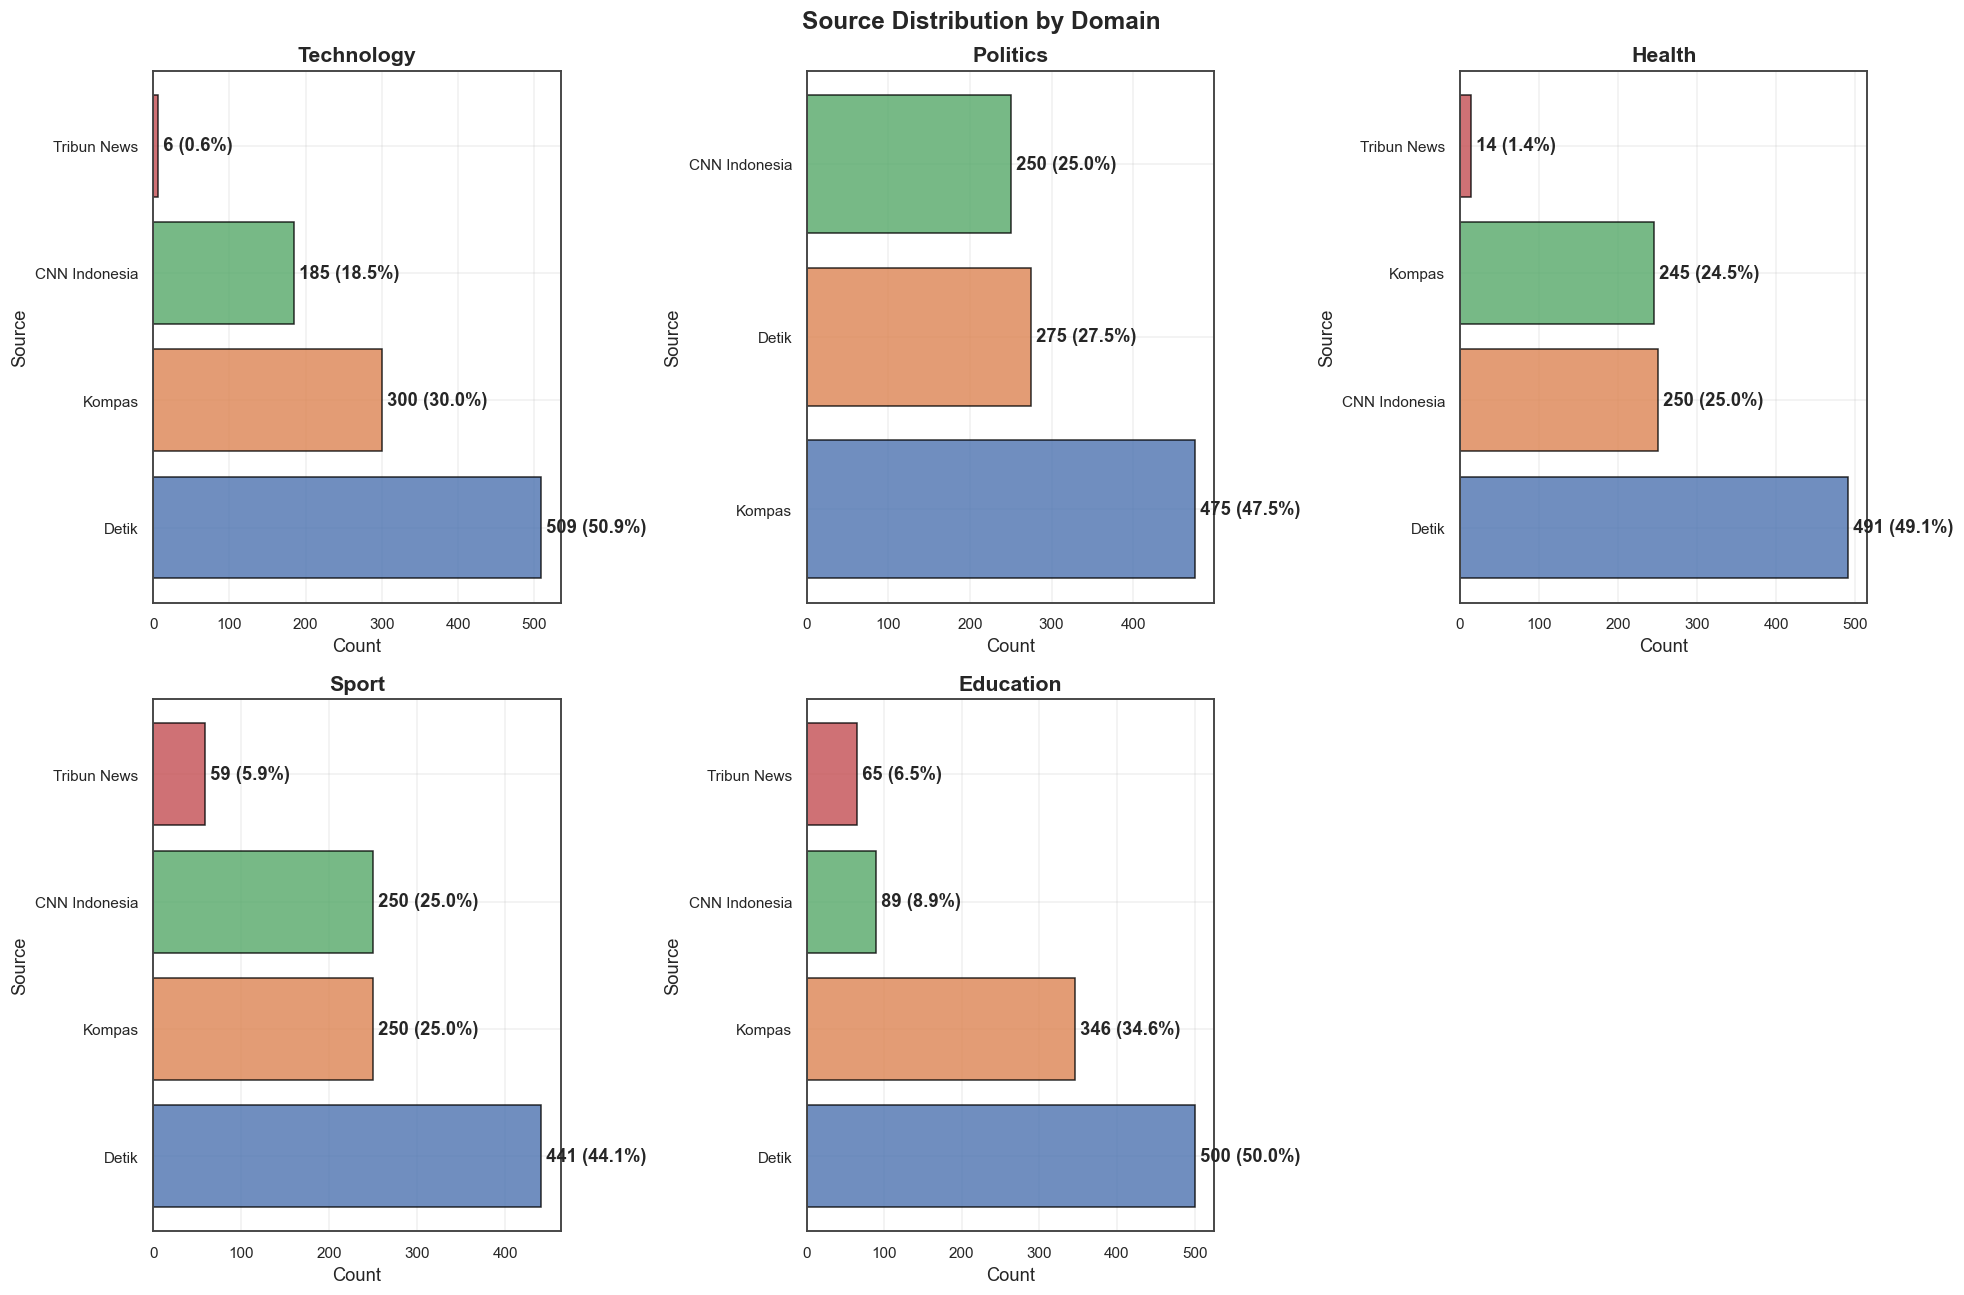

In [13]:
# ===============TABLE===============
for category, df in datasets.items():
    if 'source' in df.columns:
        print(f"\n{category} - Source Distribution:")
        source_counts = df['source'].value_counts()
        source_pct = (source_counts / len(df) * 100).round(2)
        source_df = pd.DataFrame({
            'Source': source_counts.index,
            'Count': source_counts.values,
            'Percentage': source_pct.values
        })
        display(source_df)
        print(f"Unique sources: {df['source'].nunique()}")


# ===============PLOT ===============
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for idx, (category, df) in enumerate(datasets.items()):

    if 'source' not in df.columns:
        axes[idx].axis('off')
        continue

    # Same calculation as table
    source_counts = df['source'].value_counts()
    source_pct = (source_counts / len(df) * 100).round(2)

    colors = sns.color_palette("deep", len(source_counts))

    axes[idx].barh(
        source_counts.index,
        source_counts.values,
        color=colors,
        edgecolor='black',
        alpha=0.8
    )

    axes[idx].set_title(category, fontweight='bold')
    axes[idx].set_xlabel('Count')
    axes[idx].set_ylabel('Source')
    axes[idx].grid(axis='x', alpha=0.3)

    # Count + percentage
    for i, (count, pct) in enumerate(
        zip(source_counts.values, source_pct.values)
    ):
        axes[idx].text(
            count,
            i,
            f' {count:,} ({pct:.1f}%)',
            va='center',
            fontweight='bold'
        )

# Hide unused subplot
for ax in axes[len(datasets):]:
    ax.axis('off')

plt.suptitle(
    'Source Distribution by Domain',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [14]:
### 5.2 Label Distribution
# 
# # # ===============TABLE===============
# label_data = []

# print("==========Class Imbalance Ratio==========")

# for category, df in datasets.items():
#     if 'Label' not in df.columns:
#         continue

#     label_counts = df['Label'].value_counts().sort_index()
#     label_pct = (label_counts / len(df) * 100).round(2)

#     for label in label_counts.index:
#         label_data.append({
#             'Domain': category,
#             'Label': label,
#             'Count': label_counts[label],
#             'Percentage': label_pct[label]
#         })

#     if len(label_counts) == 2:
#         imbalance_ratio = label_counts.max() / label_counts.min()
#         print(f"{category}: {imbalance_ratio:.2f} : 1")

# # Combined table
# label_df = pd.DataFrame(label_data)
# display(label_df)      


# # ===============PLOT===============
# plot_df = label_df.pivot(
#     index='Domain',
#     columns='Label',
#     values='Percentage'
# )

# ax = plot_df.plot(
#     kind='bar',
#     stacked=True,
#     figsize=(10, 6),
#     width=0.8,
#     color=[LABEL_COLORS_NUM[c] for c in plot_df.columns]
# )

# for container in ax.containers:
#     ax.bar_label(
#         container,
#         fmt='%.1f%%',
#         label_type='center',
#         fontsize=9
#     )

# plt.title('Label Distribution Across Domains')
# plt.xlabel('Domain')
# plt.ylabel('Distribution in Percentage (%)')

# plt.ylim(0, 100)

# plt.legend(
#     LABEL_ORDER,
#     title='Label',
#     loc='upper center',
#     bbox_to_anchor=(0.5, -0.08),
#     ncol=2,
#     frameon=False
# )

# plt.xticks(rotation=0)
# plt.tight_layout()
# plt.show()

### 5.2 Date Range Analysis

In [15]:
for category, df in datasets.items():
    if 'date' in df.columns:
        print(f"\n{category} - Date Analysis:")
        df['date_parsed'] = pd.to_datetime(
            df['date'], format='%d/%m/%Y', errors='coerce')
        valid_dates = df['date_parsed'].dropna()

        if len(valid_dates) > 0:
            print(f"Date Range: {valid_dates.min().date()} to {valid_dates.max().date()}")
            print(f"Total Days Span: {(valid_dates.max() - valid_dates.min()).days} days")
            print(f"Valid Dates: {len(valid_dates):,} ({len(valid_dates)/len(df)*100:.1f}%)")
            print(f"Invalid/Missing: {len(df) - len(valid_dates):,}")

            df['year'] = df['date_parsed'].dt.year
            year_dist = df['year'].value_counts().sort_index()
            print("\nYear Distribution:")
            for year, count in year_dist.items():
                if pd.notna(year):
                    print(f"  {int(year)}: {count:,} articles")


Technology - Date Analysis:
Date Range: 2025-10-03 to 2026-10-03
Total Days Span: 365 days
Valid Dates: 1,000 (100.0%)
Invalid/Missing: 0

Year Distribution:
  2025: 217 articles
  2026: 783 articles

Politics - Date Analysis:
Date Range: 2025-10-04 to 2026-10-03
Total Days Span: 364 days
Valid Dates: 1,000 (100.0%)
Invalid/Missing: 0

Year Distribution:
  2025: 72 articles
  2026: 928 articles

Health - Date Analysis:
Date Range: 2025-10-06 to 2026-10-03
Total Days Span: 362 days
Valid Dates: 1,000 (100.0%)
Invalid/Missing: 0

Year Distribution:
  2025: 195 articles
  2026: 805 articles

Sport - Date Analysis:
Date Range: 2026-05-20 to 2026-10-03
Total Days Span: 136 days
Valid Dates: 1,000 (100.0%)
Invalid/Missing: 0

Year Distribution:
  2026: 1,000 articles

Education - Date Analysis:
Date Range: 2025-10-03 to 2026-10-03
Total Days Span: 365 days
Valid Dates: 1,000 (100.0%)
Invalid/Missing: 0

Year Distribution:
  2025: 39 articles
  2026: 961 articles


In [16]:
### 4.5 URL Domain Analysis
# 
# # from urllib.parse import urlparse

# # ===============URL DOMAIN DATA===============
# url_domain_data = []
# print("==========URL Domain Analysis==========")

# for category, df in datasets.items():
#     if 'url' not in df.columns:
#         continue

#     # Extract URL domain
#     url_domains = df['url'].apply(
#         lambda x: urlparse(str(x)).netloc if pd.notna(x) else None
#     )

#     # Remove empty domains
#     url_domains = url_domains[
#         url_domains.notna() &
#         (url_domains != '')
#     ]

#     domain_counts = url_domains.value_counts().head(10)
#     print(f"\n{category} - URL Domain Analysis:")
#     print(f"Total unique domains: {url_domains.nunique()}")

#     for domain, count in domain_counts.items():
#         percentage = count / len(df) * 100
#         url_domain_data.append({
#             'Dataset_Domain': category,
#             'URL_Domain': domain,
#             'Count': count,
#             'Percentage': percentage
#         })

# url_domain_df = pd.DataFrame(url_domain_data)
# display(url_domain_df)


# # ===============PLOT: URL DOMAIN DISTRIBUTION===============

# domains = url_domain_df['Dataset_Domain'].unique()

# fig, axes = plt.subplots(
#     nrows=len(domains),
#     ncols=1,
#     figsize=(10, 4 * len(domains))
# )

# for ax, category in zip(axes, domains):
#     subset = url_domain_df[
#         url_domain_df['Dataset_Domain'] == category
#     ].sort_values('Percentage')

#     ax.barh(
#         subset['URL_Domain'],
#         subset['Percentage']
#     )

#     ax.set_title(category)
#     ax.set_xlabel('Percentage of Articles (%)')
#     ax.set_ylabel('URL Domain')

#     # Add percentage labels
#     for i, value in enumerate(subset['Percentage']):
#         ax.text(
#             value + 0.2,
#             i,
#             f'{value:.1f}%',
#             va='center',
#             fontsize=9
#         )

# fig.suptitle(
#     'Top URL Domains by Dataset Domain',
#     fontsize=15,
#     y=1.002
# )

# plt.tight_layout()
# plt.show()

### 5.3 Label Distribution

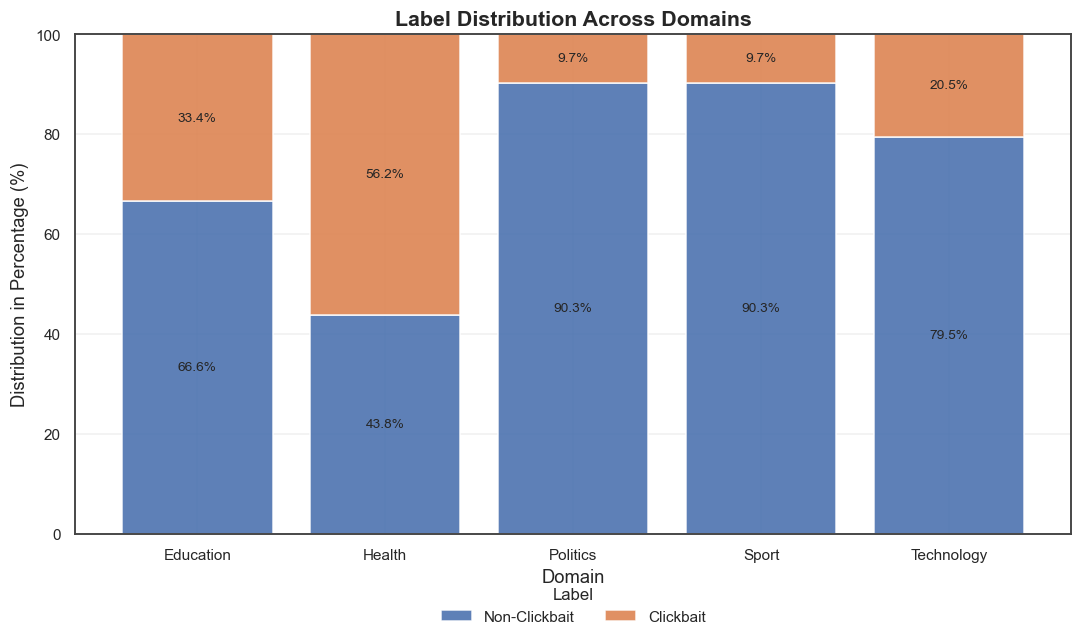

In [17]:

# =============== LABEL DISTRIBUTION ===============

plot_df = label_df.pivot(
    index='Domain',
    columns='Label',
    values='Percentage'
)

ax = plot_df.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6),
    width=0.8,
    color=[LABEL_COLORS_NUM[c] for c in plot_df.columns],
    alpha=0.9
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt='%.1f%%',
        label_type='center',
        fontsize=9
    )

ax.set(
    title='Label Distribution Across Domains',
    xlabel='Domain',
    ylabel='Distribution in Percentage (%)',
    ylim=(0, 100)
)

ax.legend(
    [LABEL_NAMES[c] for c in plot_df.columns],
    title='Label',
    loc='upper center',
    bbox_to_anchor=(0.5, -0.08),
    ncol=2,
    frameon=False
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# fig, axes = plt.subplots(2, 3, figsize=(15, 10))
# axes = axes.flatten()

# for idx, (category, df) in enumerate(datasets.items()):
#     if 'Label' in df.columns:
#         label_counts = df['Label'].value_counts().sort_index()
#         axes[idx].bar(label_counts.index.astype(str), label_counts.values,
#                      color=[LABEL_COLORS_NUM[i] for i in label_counts.index], edgecolor='black', alpha=0.8)
#         axes[idx].set_title(f'{category}\n(n={len(df):,})', fontweight='bold')
#         axes[idx].set_xlabel('Label')
#         axes[idx].set_ylabel('Count')
#         axes[idx].grid(axis='y', alpha=0.3)

#         for i, v in enumerate(label_counts.values):
#             axes[idx].text(i, v, f'{v:,}', ha='center', va='bottom', fontweight='bold')

# axes[-1].axis('off')
# plt.suptitle('Label Distribution Across All Datasets', fontsize=16, fontweight='bold')
# plt.tight_layout()
# plt.show()

In [18]:

### 6.2 Source Distribution

# # ===============PLOT===============
# fig, axes = plt.subplots(2, 3, figsize=(18, 12))
# axes = axes.flatten()

# for idx, (category, df) in enumerate(datasets.items()):
#     if 'source' in df.columns:
#         source_counts = df['source'].value_counts()
#         colors = sns.color_palette("deep", len(source_counts))
#         axes[idx].barh(source_counts.index, source_counts.values, color=colors, edgecolor='black', alpha=0.8)
#         axes[idx].set_title(f'{category}', fontweight='bold')
#         axes[idx].set_xlabel('Count')
#         axes[idx].grid(axis='x', alpha=0.3)

#         for i, v in enumerate(source_counts.values):
#             axes[idx].text(v, i, f' {v:,}', va='center', fontweight='bold')

# axes[-1].axis('off')
# plt.suptitle('Source Distribution', fontsize=16, fontweight='bold')
# plt.tight_layout()
# plt.show()

### 5.4 Article Count Over Time

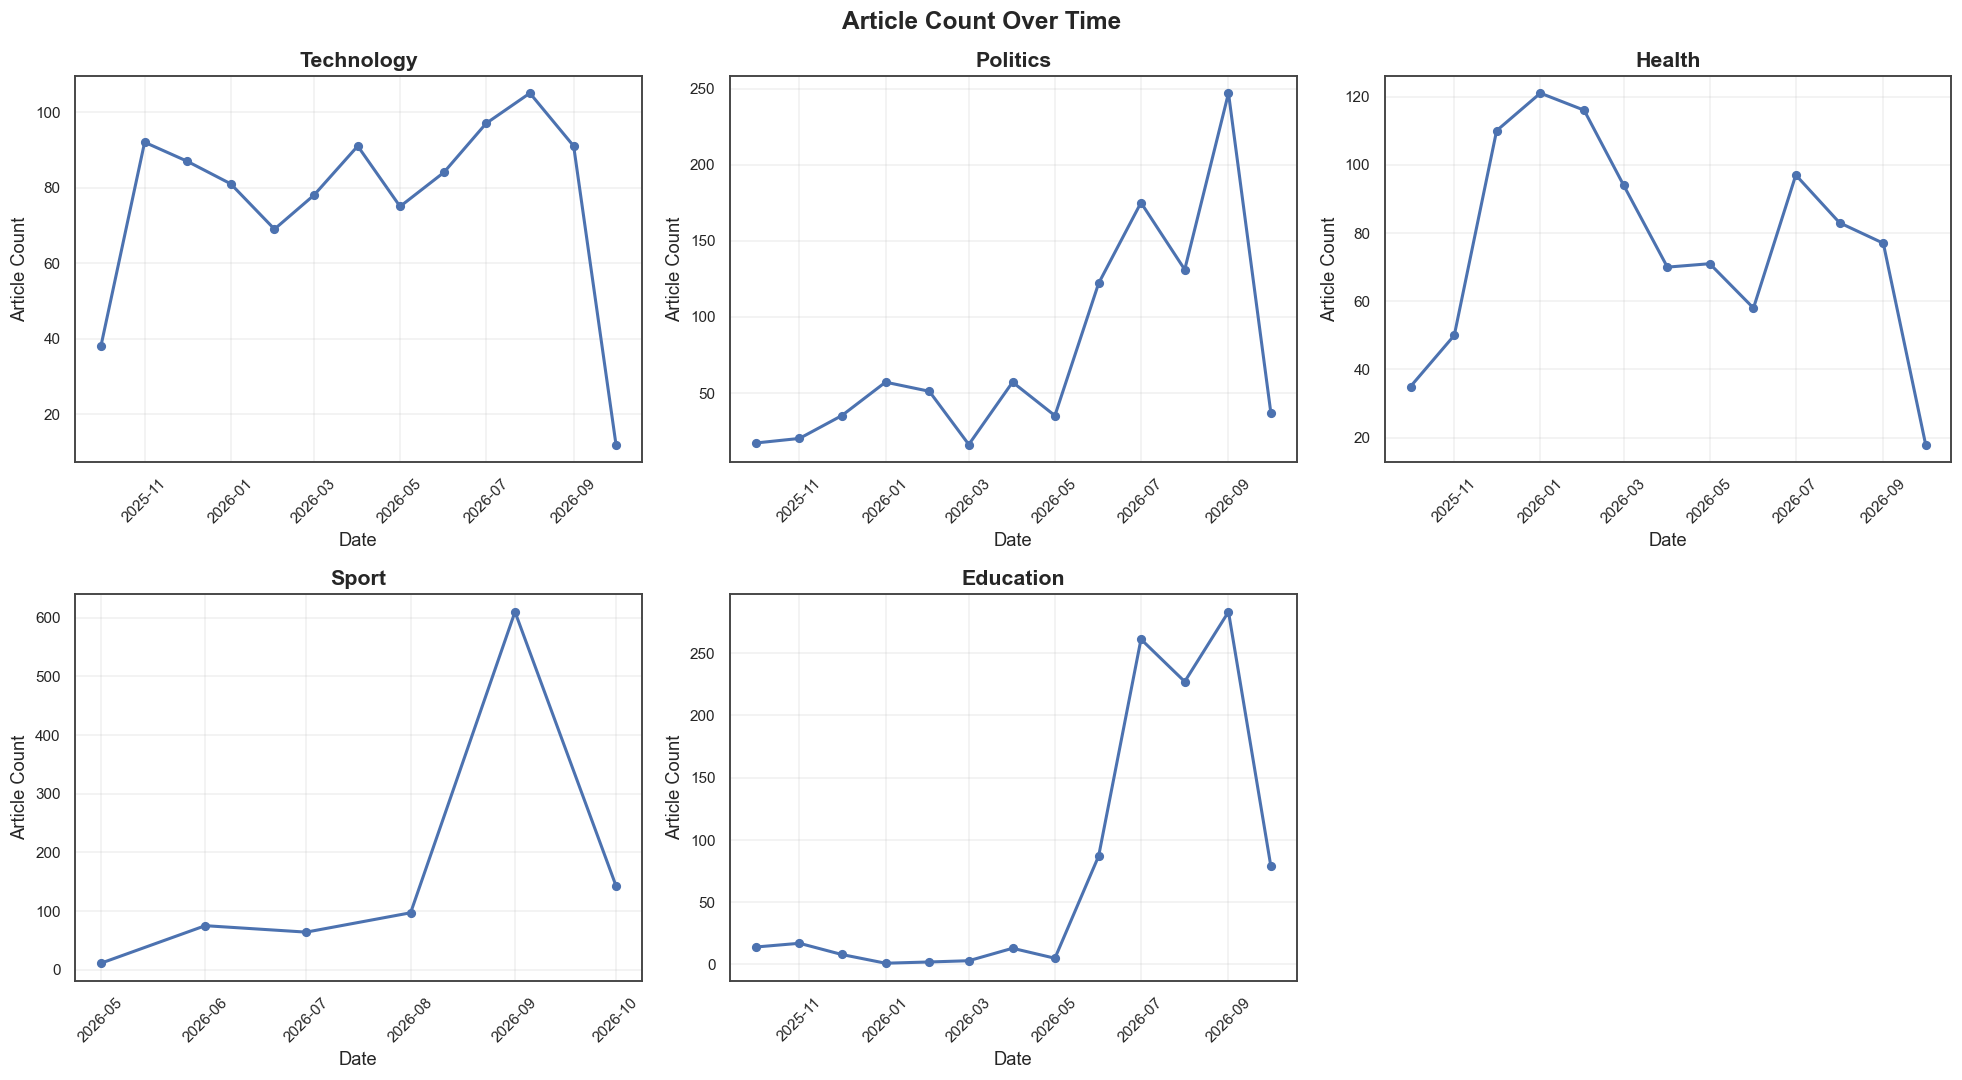

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (category, df) in enumerate(datasets.items()):
    if 'date' in df.columns:
        df['date_parsed'] = pd.to_datetime(df['date'], errors='coerce', format='%d/%m/%Y')
        df['year_month'] = df['date_parsed'].dt.to_period('M')
        monthly_counts = df['year_month'].value_counts().sort_index()

        if len(monthly_counts) > 0:
            x_values = [period.to_timestamp() for period in monthly_counts.index]
            axes[idx].plot(x_values, monthly_counts.values, marker='o', linewidth=2, markersize=5)
            axes[idx].set_title(f'{category}', fontweight='bold')
            axes[idx].set_xlabel('Date')
            axes[idx].set_ylabel('Article Count')
            axes[idx].grid(True, alpha=0.3)
            axes[idx].tick_params(axis='x', rotation=45)

axes[-1].axis('off')
plt.suptitle('Article Count Over Time', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

### 5.5 Title Length Distribution

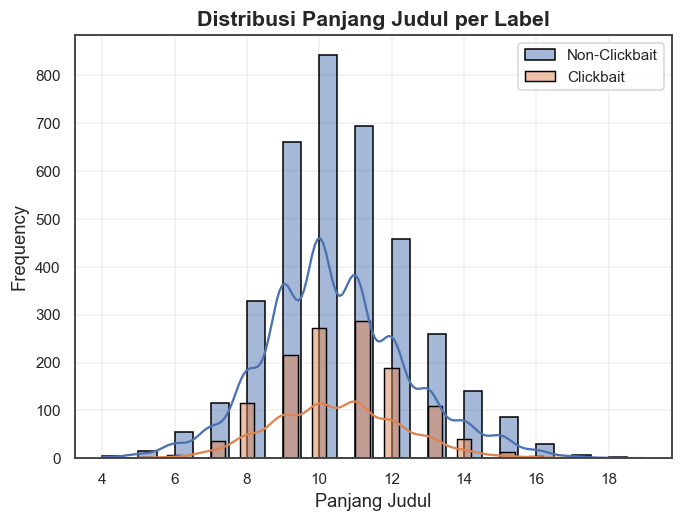

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------------------------------------
# Combined frame built ONCE here (first cell that needs it) and
# reused by every later Section 5/9 cell. All length features are
# derived here so nothing downstream has to recompute them.
# ---------------------------------------------------------------
all_df = pd.concat(
    [d.assign(Domain=category) for category, d in datasets.items()],
    ignore_index=True,
)
all_df["Label"] = pd.to_numeric(all_df["Label"], errors="coerce").astype("Int64")
all_df["Label_num"] = pd.to_numeric(all_df["Label"], errors="coerce")
all_df["Label_Name"] = all_df["Label"].map(LABEL_NAMES)
all_df["title"] = all_df["title"].astype(str)
all_df["char_len"] = all_df["title"].str.len()
all_df["word_len"] = all_df["title"].str.split().apply(len)
all_df["title_len"] = all_df["word_len"]   # word-based title length (alias)

plt.figure(figsize=(7,5))

sns.histplot(
    all_df[all_df["Label"]==0]["title_len"],
    color="#4C72B0",
    label="Non-Clickbait",
    kde=True,
    bins=30,
    alpha=0.5,
    edgecolor="black",
)

sns.histplot(
    all_df[all_df["Label"]==1]["title_len"],
    color="#DD8452",
    label="Clickbait",
    kde=True,
    bins=30,
    alpha=0.5,
    edgecolor="black",
)

plt.title("Distribusi Panjang Judul per Label")
plt.xlabel("Panjang Judul")
plt.ylabel("Frequency")

plt.legend()
plt.show() 

### 5.6 Top Frequent Words by Domain and Label

In [21]:
# import matplotlib.pyplot as plt
# import numpy as np
# import pandas as pd
# from sklearn.feature_extraction.text import CountVectorizer

# domains = DOMAINS

# fig, axes = plt.subplots(
#     nrows=len(domains), ncols=2, figsize=(14, 4.5 * len(domains))
# )

# for row, domain in enumerate(domains):
#     df = datasets[domain]

#     for col, label in enumerate([0, 1]):
#         ax = axes[row, col]

#         # Filter judul berdasarkan label
#         titles = df[df["Label"] == label]["title"].astype(str)

#         # Inisialisasi CountVectorizer TANPA stop_words filter
#         vectorizer = CountVectorizer(max_features=10, stop_words=None)

#         X = vectorizer.fit_transform(titles)

#         word_counts = np.sum(X.toarray(), axis=0)
#         words = vectorizer.get_feature_names_out()

#         top_words = pd.DataFrame({"word": words, "count": word_counts})

#         top_words = top_words.sort_values(by="count", ascending=True)

#         # Plot horizontal bar chart
#         bar_color = "#4C72B0" if label == 0 else "#DD8452"
#         ax.barh(top_words["word"], top_words["count"], color=bar_color)
#         ax.set_title(
#             f"{domain} — {LABEL_NAMES[label]}", fontweight="bold", fontsize=11
#         )
#         ax.set_xlabel("Word Count", fontsize=9)
#         ax.set_ylabel("Word", fontsize=9)
#         ax.grid(True, alpha=0.3, axis="x")

# # Overall title
# fig.suptitle(
#     "Top Frequent Words in Titles by Domain and Label (Unfiltered / Full Vocabulary)",
#     fontsize=15,
#     fontweight="bold",
#     y=1.002,
# )

# plt.tight_layout()
# plt.show()

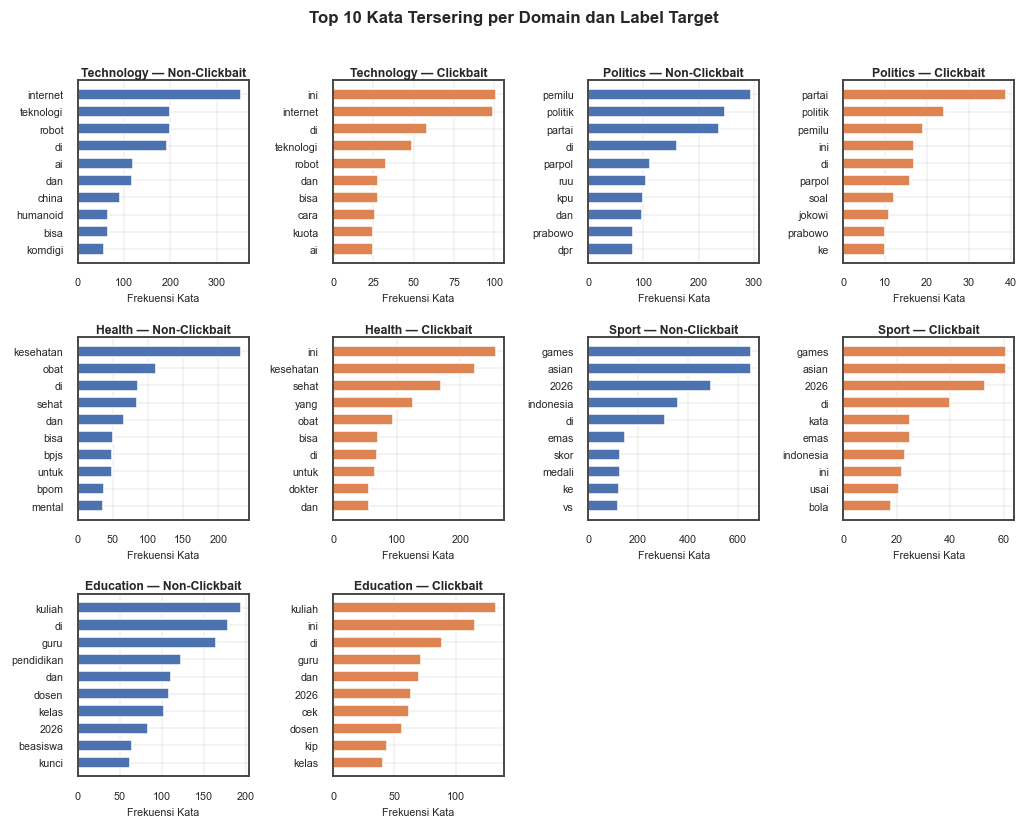

In [22]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer

domains = DOMAINS

# 3 rows x 4 columns layout
# Width = 9.5 inches (good for landscape orientation or wider Word layout)
# Height = 7.5 inches (compact vertical footprint)
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(9.5, 7.5))
axes_flat = axes.flatten()

plot_idx = 0

for domain in domains:
  df_domain = datasets[domain]

  for label in [0, 1]:
    ax = axes_flat[plot_idx]

    # Filter titles by label
    titles = df_domain[df_domain["Label"] == label]["title"].astype(str)

    # Extract top 10 words (unfiltered vocabulary)
    vectorizer = CountVectorizer(max_features=10, stop_words=None)
    X = vectorizer.fit_transform(titles)

    word_counts = np.sum(X.toarray(), axis=0)
    words = vectorizer.get_feature_names_out()

    df_words = pd.DataFrame(
        {"word": words, "count": word_counts}
    ).sort_values(by="count", ascending=True)

    # Plot horizontal bars
    color = "#4C72B0" if label == 0 else "#DD8452"
    ax.barh(df_words["word"], df_words["count"], color=color, height=0.65)

    # Subplot titles and font adjustments tuned for 4-column width
    ax.set_title(
        f"{domain} — {LABEL_NAMES[label]}", fontweight="bold", fontsize=8, pad=3
    )
    ax.set_xlabel("Frekuensi Kata", fontsize=7)
    ax.tick_params(axis="both", labelsize=7)
    ax.grid(True, alpha=0.3, axis="x")

    plot_idx += 1

# Hide the 2 remaining unused subplots (indices 10 and 11)
for i in range(plot_idx, len(axes_flat)):
  axes_flat[i].axis("off")

# Main Title
fig.suptitle(
    "Top 10 Kata Tersering per Domain dan Label Target",
    fontweight="bold",
    fontsize=11,
    y=1.002,
)

plt.tight_layout()
plt.savefig("top_words_3x4_grid.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# # =========================
# # TOP FREQUENT WORDS BY DOMAIN AND LABEL
# # =========================

# from sklearn.feature_extraction.text import CountVectorizer
# from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# # Stopwords used only for this analysis
# stopwords = StopWordRemoverFactory().get_stop_words()
# domains = DOMAINS

# fig, axes = plt.subplots(
#     nrows=len(domains),
#     ncols=2,
#     figsize=(14, 5 * len(domains))
# )

# for row, domain in enumerate(domains):
#     df = datasets[domain]

#     for col, label in enumerate([0, 1]):
#         ax = axes[row, col]
#         # Select titles for this label
#         titles = df[
#             df['Label'] == label
#         ]['title'].astype(str)

#         # Count words after removing stopwords
#         vectorizer = CountVectorizer(
#             max_features=10,
#             stop_words=stopwords
#         )

#         X = vectorizer.fit_transform(titles)

#         word_counts = np.sum(X.toarray(), axis=0)
#         words = vectorizer.get_feature_names_out()

#         top_words = pd.DataFrame({
#             'word': words,
#             'count': word_counts
#         })

#         top_words = top_words.sort_values(
#             by='count',
#             ascending=True
#         )

#         # Plot
#         ax.barh(
#             top_words['word'],
#             top_words['count']
#         )
#         ax.set_title(
#             f'{domain} - {LABEL_NAMES[label]}'
#         )
#         ax.set_xlabel('Word Count')
#         ax.set_ylabel('Word')

# # Overall title
# fig.suptitle(
#     'Top Frequent Words in Titles by Domain and Label',
#     fontsize=16,
#     y=1.002
# )

# plt.tight_layout()
# plt.show()

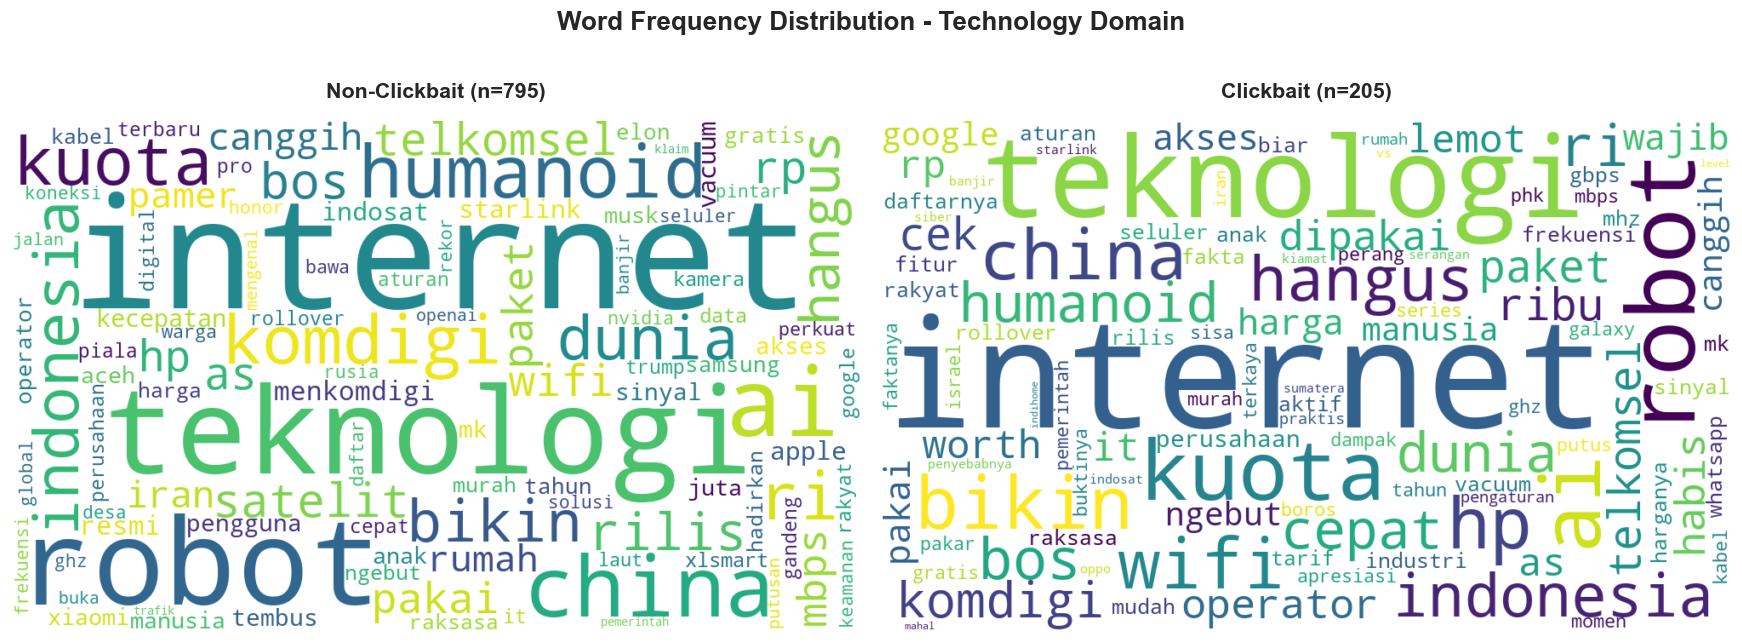

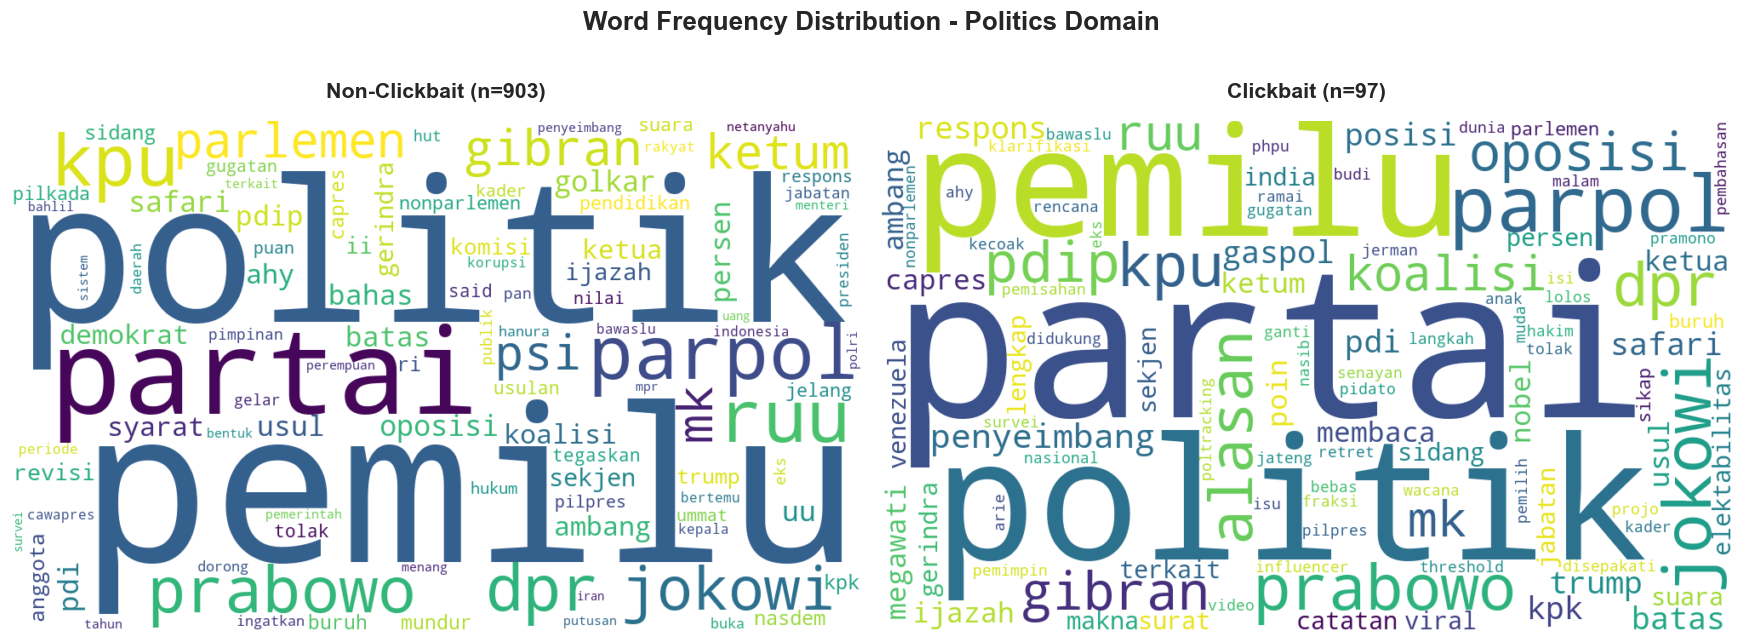

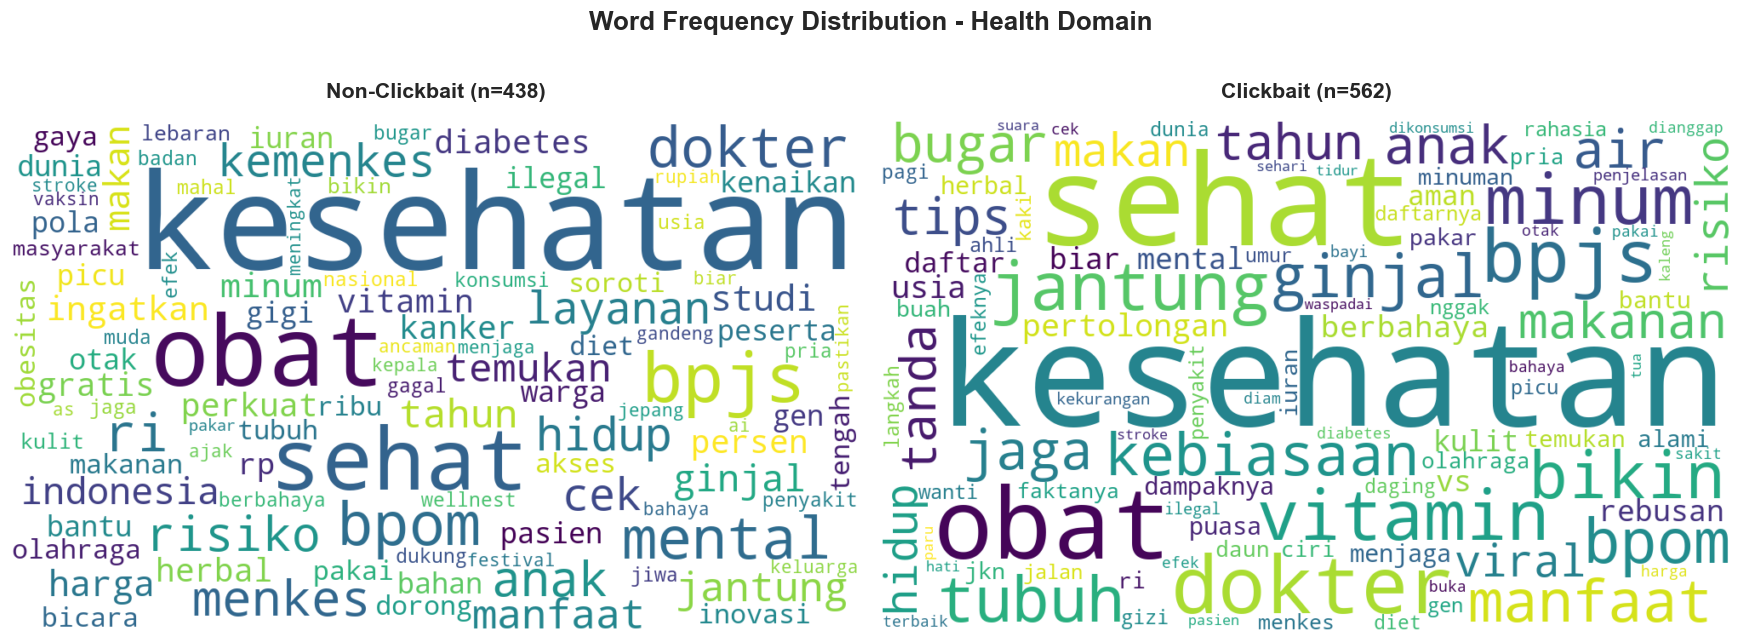

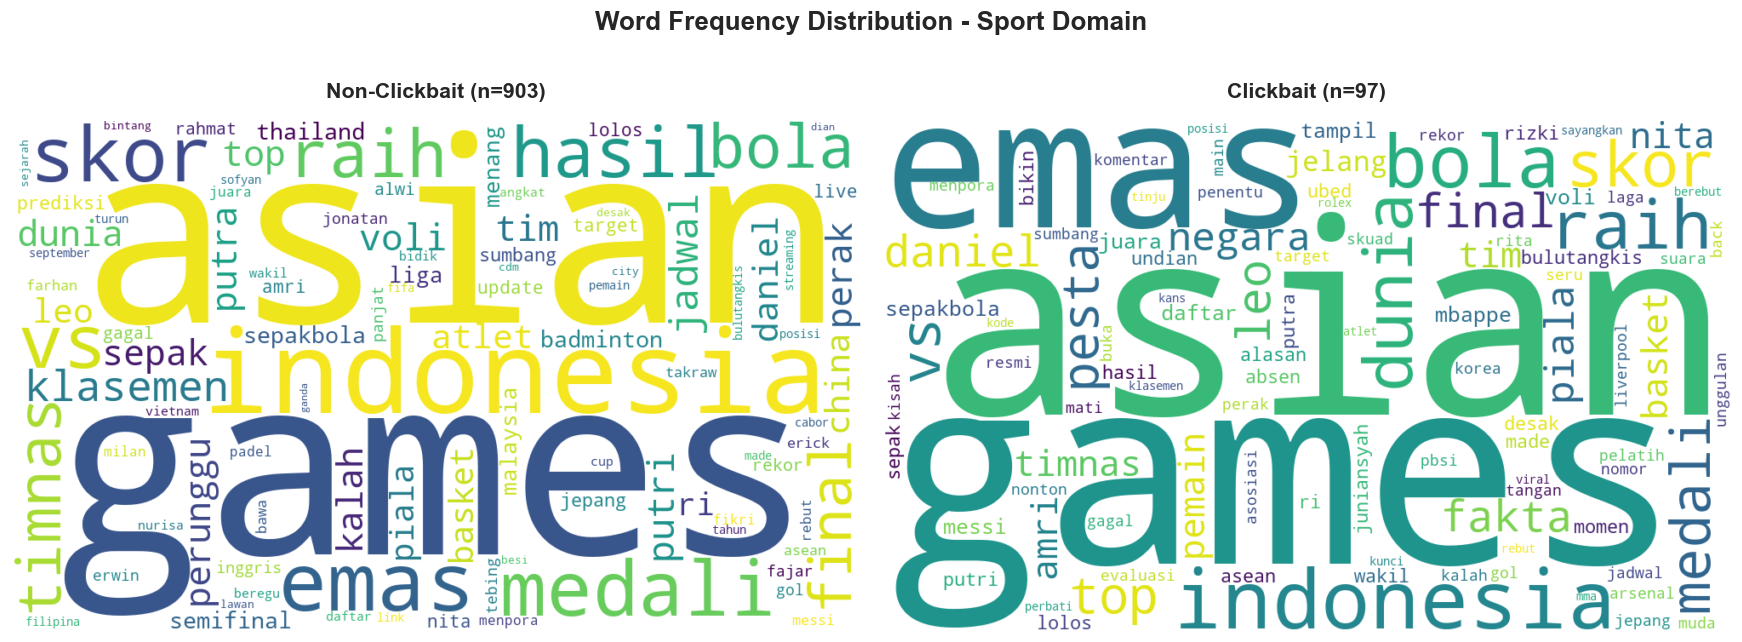

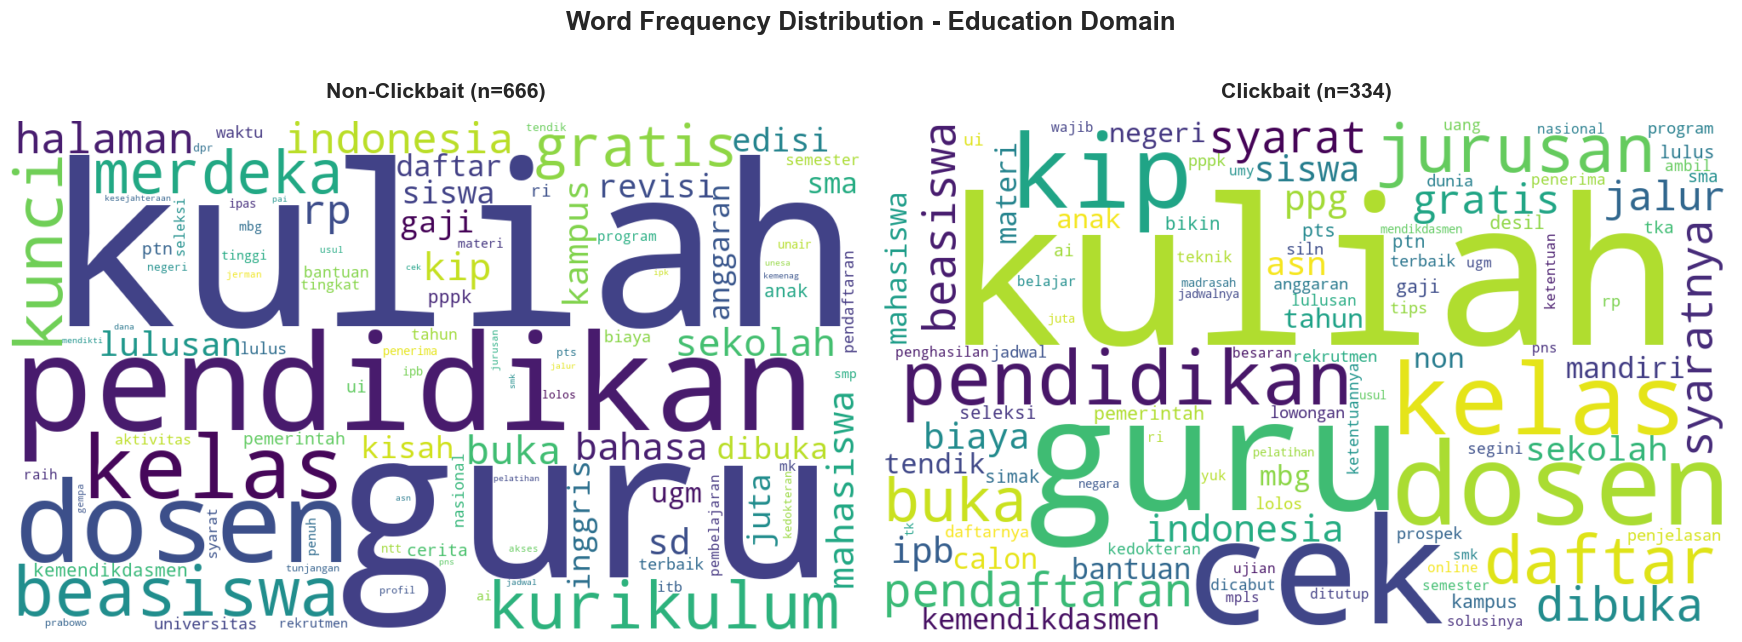

In [24]:
# -- GRAPH 10.3: Word Cloud by Domain and Clickbait Label --

import re
from collections import Counter
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

# Indonesian stopwords
stopwords = set(StopWordRemoverFactory().get_stop_words())

domains = DOMAINS
labels = [0, 1]

# Generate one figure for each domain
for domain in domains:

    df = datasets[domain]

    fig, axes = plt.subplots(
        nrows=1,
        ncols=2,
        figsize=(16, 6)
    )

    for idx, label in enumerate(labels):

        ax = axes[idx]

        # Filter titles by label
        label_df = df[df["Label"] == label]

        # Collect words
        all_words = []

        for title in label_df["title"].dropna():

            words = re.findall(r"[a-zA-Z]+", str(title).lower())

            words = [
                word for word in words
                if word not in stopwords
            ]

            all_words.extend(words)

        # Calculate word frequencies
        word_freq = Counter(all_words)

        if not word_freq:
            ax.set_title(f"{LABEL_NAMES[label]} (n={len(label_df):,})")
            ax.text(0.5, 0.5, "No words available",
                    ha="center", va="center")
            ax.axis("off")
            continue

        # Generate Word Cloud
        wordcloud = WordCloud(
            width=1000,
            height=600,
            background_color="white",
            colormap="viridis",
            max_words=100,
            collocations=False
        ).generate_from_frequencies(word_freq)

        # Display Word Cloud
        ax.imshow(wordcloud, interpolation="bilinear")

        ax.set_title(
            f"{LABEL_NAMES[label]} (n={len(label_df):,})",
            fontsize=14,
            fontweight="bold",
            pad=15
        )

        ax.axis("off")

    # Domain title
    fig.suptitle(
        f"Word Frequency Distribution - {domain} Domain",
        fontsize=17,
        fontweight="bold",
        y=0.98
    )

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

### 5.7 Feature Correlation Matrix

            title_len  Domain_enc  Source_enc  Label_num
title_len    1.000000   -0.155817    0.304466   0.013918
Domain_enc  -0.155817    1.000000   -0.076815  -0.233396
Source_enc   0.304466   -0.076815    1.000000  -0.070553
Label_num    0.013918   -0.233396   -0.070553   1.000000


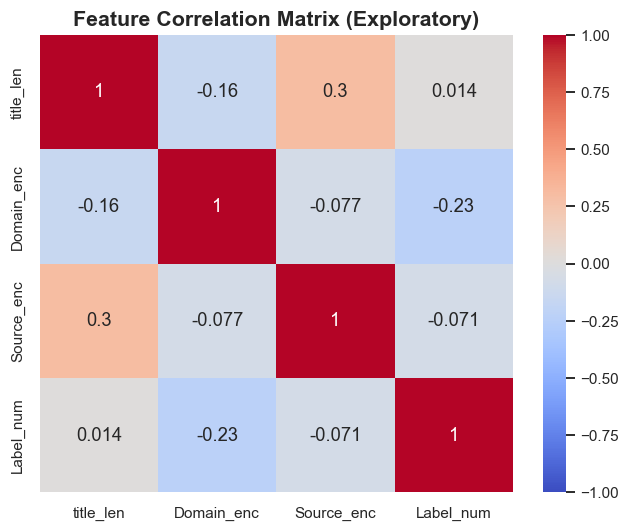

In [25]:
from sklearn.preprocessing import LabelEncoder

# Encode categorical columns on the shared all_df (length features
# title_len / Label_num already exist from the combined build).
le_domain = LabelEncoder()
all_df["Domain_enc"] = le_domain.fit_transform(all_df["Domain"])

le_source = LabelEncoder()
all_df["Source_enc"] = le_source.fit_transform(all_df["source"].astype(str))

# Correlation on aligned, equal-length columns
corr = all_df[["title_len", "Domain_enc", "Source_enc", "Label_num"]].corr()
print(corr)

# =============PLOT=========================
plt.figure(figsize=(6, 5))

sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)

plt.title("Feature Correlation Matrix (Exploratory)")
plt.tight_layout()
plt.show()


### 5.8 Pearson Correlation & Cramér's V Association Matrix

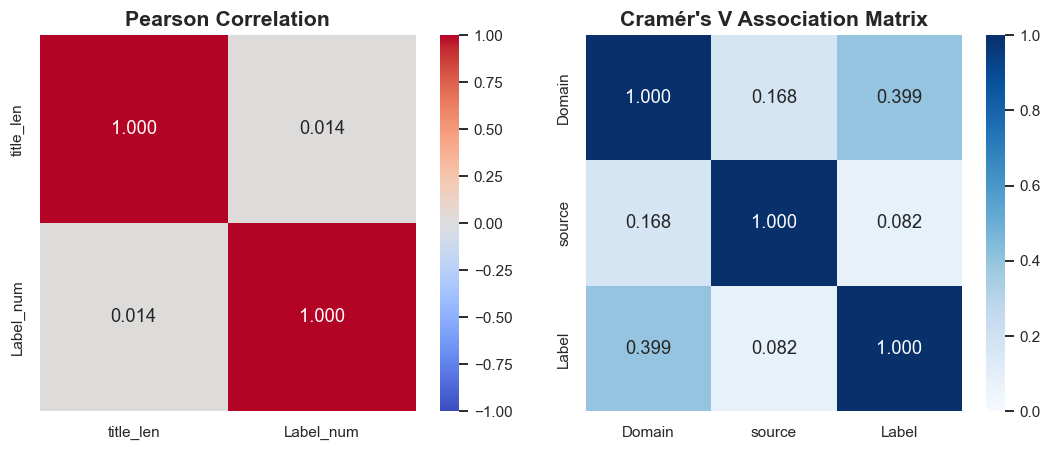

In [26]:
from scipy.stats import chi2_contingency


# =========================
# Cramér's V function
# =========================
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    n = table.values.sum()
    r, k = table.shape

    denom = n * min(r - 1, k - 1)
    return np.sqrt(chi2 / denom) if denom > 0 else 0.0


# =========================
# Calculate Pearson
# =========================
pearson_corr = all_df[['title_len', 'Label_num']].corr()


# =========================
# Calculate Cramér's V
# =========================
cols = ['Domain', 'source', 'Label']

cramers_matrix = pd.DataFrame(
    index=cols,
    columns=cols,
    dtype=float
)

for col1 in cols:
    for col2 in cols:
        if col1 == col2:
            cramers_matrix.loc[col1, col2] = 1
        else:
            cramers_matrix.loc[col1, col2] = cramers_v(
                all_df[col1],
                all_df[col2]
            )


# =========================
# Plot side by side
# =========================
fig, axes = plt.subplots(
    1, 2,
    figsize=(10, 4)
)

# Pearson
sns.heatmap(
    pearson_corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True,
    ax=axes[0]
)
axes[0].set_title('Pearson Correlation')

# Cramér's V
sns.heatmap(
    cramers_matrix,
    annot=True,
    fmt='.3f',
    cmap='Blues',
    vmin=0,
    vmax=1,
    square=True,
    ax=axes[1]
)
axes[1].set_title("Cramér's V Association Matrix")

plt.tight_layout()
plt.show()


### 5.9 Unique Vocabulary for Each Domain

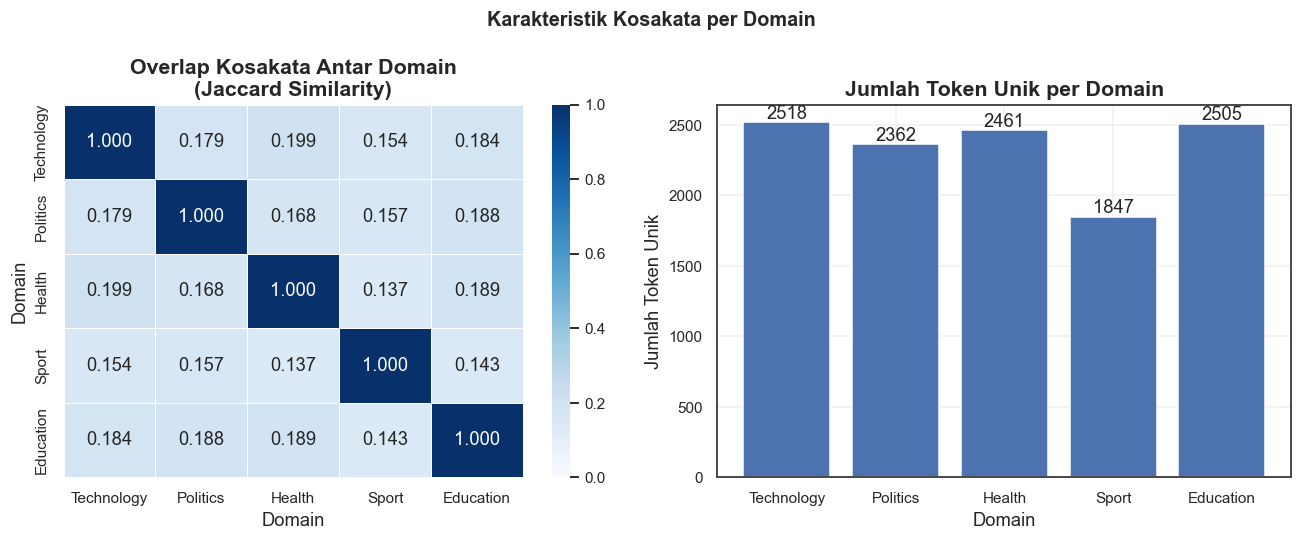

In [27]:
# ═══════════════════════════════════════════════════════════
# VISUALISASI 6 — Kosakata Antar Domain
# ═══════════════════════════════════════════════════════════

import re

# Tokenize titles
def tokenize(text):
    return set(
        re.sub(r"[^a-zA-Z\s]", "", str(text).lower()).split()
    )


# Get unique vocabulary for each domain
domain_vocab = {}

for domain in domains:
    titles = all_df[all_df["Domain"] == domain]["title"]
    vocab = set()

    for title in titles:
        vocab.update(tokenize(title))

    domain_vocab[domain] = vocab


# Calculate Jaccard similarity
jaccard_matrix = pd.DataFrame(
    index=domains,
    columns=domains,
    dtype=float
)

for d1 in domains:
    for d2 in domains:
        vocab1 = domain_vocab[d1]
        vocab2 = domain_vocab[d2]

        union = len(vocab1 | vocab2)
        if union == 0:
            jaccard_matrix.loc[d1, d2] = 0
        else:
            jaccard_matrix.loc[d1, d2] = (
                len(vocab1 & vocab2) / union
            )


# =========================
# PLOT
# =========================

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

fig.suptitle(
    "Karakteristik Kosakata per Domain",
    fontsize=13,
    fontweight="bold"
)

# cc heatmap
sns.heatmap(
    jaccard_matrix,
    annot=True,
    fmt=".3f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title("Overlap Kosakata Antar Domain\n(Jaccard Similarity)")
axes[0].set_xlabel("Domain")
axes[0].set_ylabel("Domain")


# Vocabulary size
vocab_sizes = [
    len(domain_vocab[domain])
    for domain in domains
]

axes[1].bar(
    domains,
    vocab_sizes
)

axes[1].set_title("Jumlah Token Unik per Domain")
axes[1].set_xlabel("Domain")
axes[1].set_ylabel("Jumlah Token Unik")

for i, value in enumerate(vocab_sizes):
    axes[1].text(
        i,
        value,
        str(value),
        ha="center",
        va="bottom"
    )


plt.tight_layout()
plt.show()

In [28]:
## 7. Comparative Analysis
### 7.1 Dataset Size Comparison

### 5.10 Source Diversity


Source Diversity Summary:


,Category,Unique Sources,Total Articles,Avg per Source
0,Technology,4,1000,250.0
1,Politics,3,1000,333.3
2,Health,4,1000,250.0
3,Sport,4,1000,250.0
4,Education,4,1000,250.0


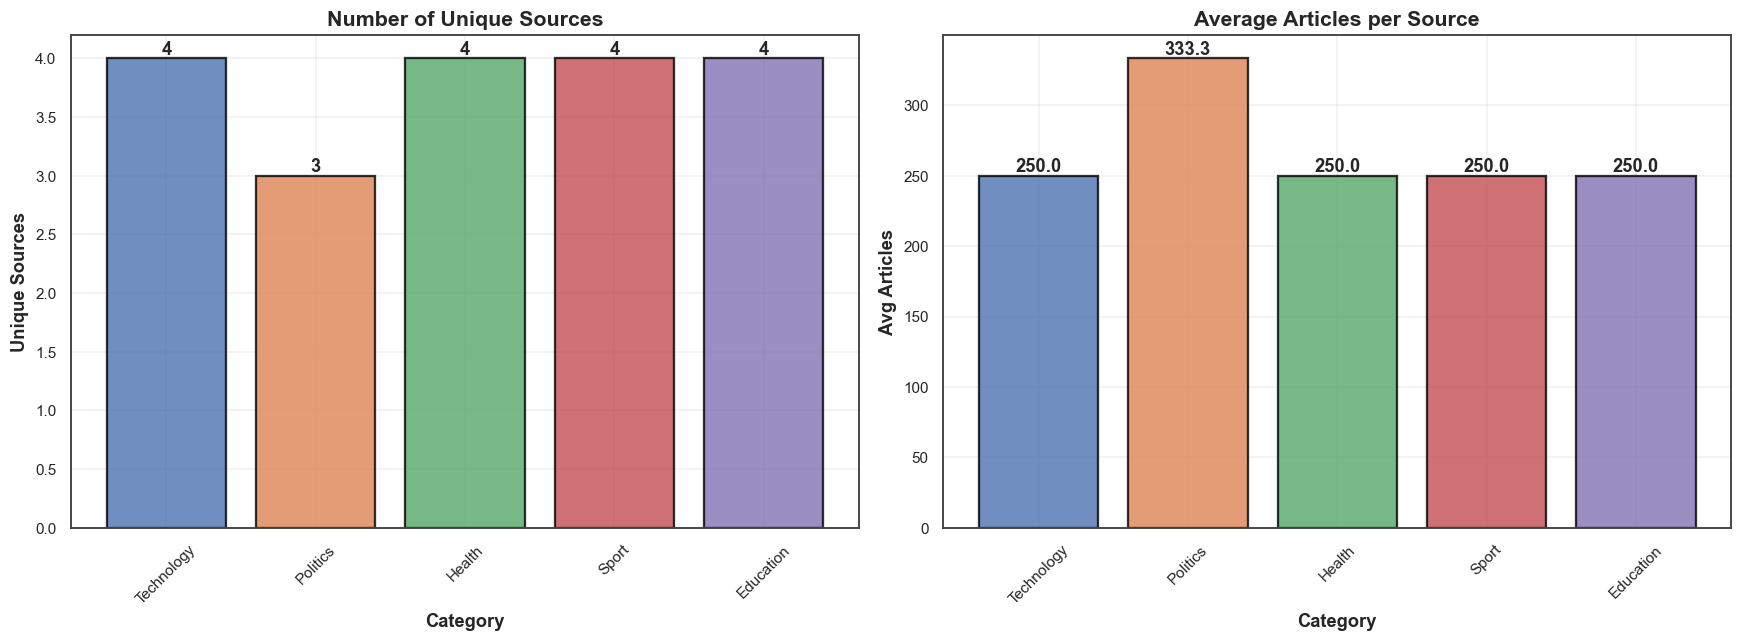

In [29]:
source_diversity = []

for category, df in datasets.items():
    if "source" in df.columns:
        unique_sources = df["source"].nunique()
        total_articles = len(df)

        source_diversity.append(
            {
                "Category": category,
                "Unique Sources": unique_sources,
                "Total Articles": total_articles,
                "Avg per Source": round(
                    total_articles / unique_sources, 1
                )
                if unique_sources > 0
                else 0,
            }
        )

if source_diversity:
    diversity_df = pd.DataFrame(source_diversity)
    fig, (ax1, ax2) = plt.subplots(
        1, 2,
        figsize=(16, 6)
    )

    ax1.bar(
        diversity_df["Category"],
        diversity_df["Unique Sources"],
        color=[
            DOMAIN_COLORS.get(c, "#4C72B0")
            for c in diversity_df["Category"]
        ],
        edgecolor="black",
        linewidth=1.5,
        alpha=0.8,
    )

    ax1.set_title(
        "Number of Unique Sources",
        fontsize=14,
        fontweight="bold"
    )

    ax1.set_xlabel(
        "Category",
        fontweight="bold"
    )

    ax1.set_ylabel(
        "Unique Sources",
        fontweight="bold"
    )

    ax1.tick_params(
        axis="x",
        rotation=45
    )

    ax1.grid(
        axis="y",
        alpha=0.3
    )

    for i, v in enumerate(diversity_df["Unique Sources"]):
        ax1.text(
            i,
            v,
            str(v),
            ha="center",
            va="bottom",
            fontweight="bold"
        )

    ax2.bar(
        diversity_df["Category"],
        diversity_df["Avg per Source"],
        color=[
            DOMAIN_COLORS.get(c, "#4C72B0")
            for c in diversity_df["Category"]
        ],
        edgecolor="black",
        linewidth=1.5,
        alpha=0.8,
    )

    ax2.set_title(
        "Average Articles per Source",
        fontsize=14,
        fontweight="bold"
    )

    ax2.set_xlabel(
        "Category",
        fontweight="bold"
    )

    ax2.set_ylabel(
        "Avg Articles",
        fontweight="bold"
    )

    ax2.tick_params(
        axis="x",
        rotation=45
    )

    ax2.grid(
        axis="y",
        alpha=0.3
    )

    for i, v in enumerate(diversity_df["Avg per Source"]):
        ax2.text(
            i,
            v,
            f"{v:.1f}",
            ha="center",
            va="bottom",
            fontweight="bold"
        )

    print("\nSource Diversity Summary:")
    display(diversity_df)
    
    plt.tight_layout()
    plt.show()

In [30]:
### 7.4 Data Quality Comparison
# 
# # quality_data = []
# for category, df in datasets.items():
#     quality_data.append({
#         'Category': category,
#         'Total Rows': len(df),
#         'Missing Values': df.isnull().sum().sum(),
#         'Duplicate Rows': df.duplicated().sum(),
#         'Duplicate Titles': df['title'].duplicated().sum() if 'title' in df.columns else 0,
#         'Duplicate URLs': df['url'].duplicated().sum() if 'url' in df.columns else 0
#     })

# quality_df = pd.DataFrame(quality_data)
# print("\nData Quality Comparison:")
# display(quality_df)

# fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# axes[0].bar(quality_df['Category'], quality_df['Missing Values'],
#            color=LABEL_COLORS['Clickbait'], edgecolor='black', alpha=0.8)
# axes[0].set_title('Missing Values', fontweight='bold')
# axes[0].set_ylabel('Count')
# axes[0].tick_params(axis='x', rotation=45)
# axes[0].grid(axis='y', alpha=0.3)

# axes[1].bar(quality_df['Category'], quality_df['Duplicate Titles'],
#            color=LABEL_COLORS['Non-Clickbait'], edgecolor='black', alpha=0.8)
# axes[1].set_title('Duplicate Titles', fontweight='bold')
# axes[1].set_ylabel('Count')
# axes[1].tick_params(axis='x', rotation=45)
# axes[1].grid(axis='y', alpha=0.3)

# axes[2].bar(quality_df['Category'], quality_df['Duplicate URLs'],
#            color=sns.color_palette("deep")[2], edgecolor='black', alpha=0.8)
# axes[2].set_title('Duplicate URLs', fontweight='bold')
# axes[2].set_ylabel('Count')
# axes[2].tick_params(axis='x', rotation=45)
# axes[2].grid(axis='y', alpha=0.3)

# plt.tight_layout()
# plt.show()

### 5.11 Title-Length (Characters & Words)

Descriptive statistics for title length, then box plots, violin plots, and histograms to expose extremely short/long titles (outliers) overall, by domain, and by label.

In [31]:
# all_df (with char_len / word_len / Label_Name) is built once in Section 5.
print("Combined dataset:", all_df.shape)
print("Domains:", DOMAINS)


Combined dataset: (5000, 17)
Domains: ['Technology', 'Politics', 'Health', 'Sport', 'Education']



Title Length Descriptive Statistics (overall)


,Characters,Words
count,5000.00,5000.00
mean,68.50,10.46
std,11.31,1.94
min,22.00,4.00
Q1,62.00,9.00
median,68.00,10.00
Q3,75.00,12.00
max,119.00,19.00



Title Length Outliers via 1.5 x IQR rule


,Metric,Lower Bound,Upper Bound,Outliers (n),Outliers (%)
0,Characters,42.5,94.5,179,3.58
1,Words,4.5,16.5,16,0.32


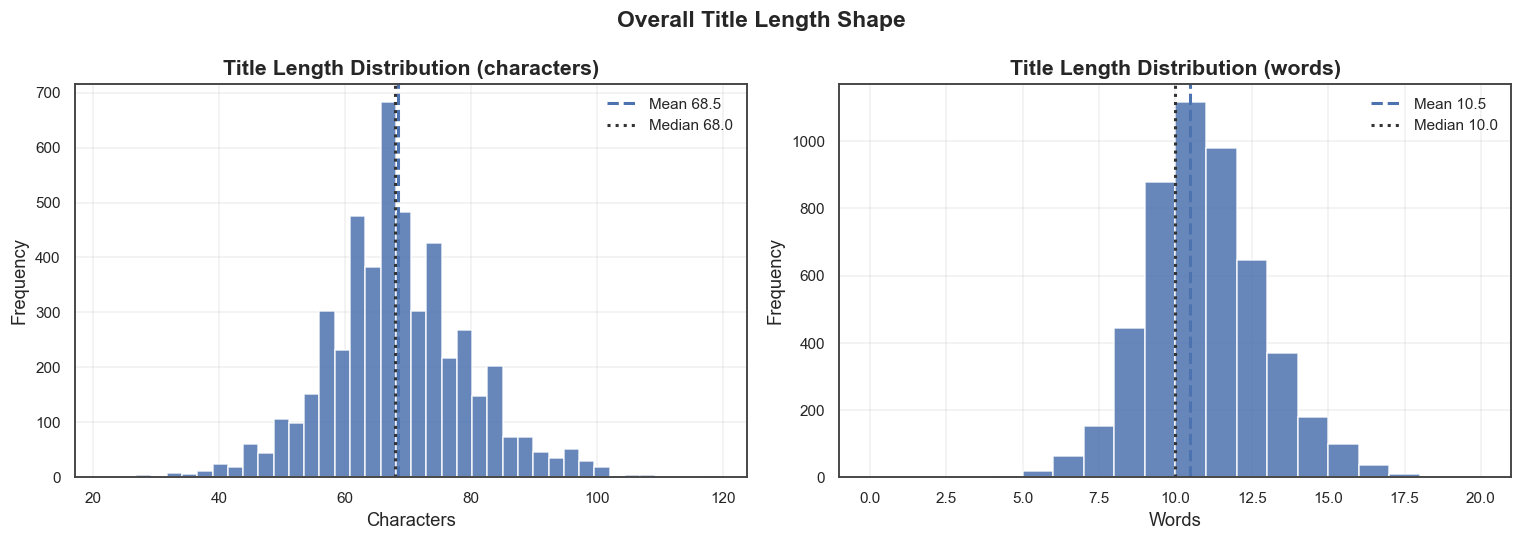

In [32]:
# =============== DESCRIPTIVE STATISTICS ===============

def describe_len(col):
    s = all_df[col]

    return pd.Series({
        "count": s.count(),
        "mean": s.mean(),
        "std": s.std(),
        "min": s.min(),
        "Q1": s.quantile(0.25),
        "median": s.median(),
        "Q3": s.quantile(0.75),
        "max": s.max()
    })


len_stats = pd.DataFrame({
    "Characters": describe_len("char_len"),
    "Words": describe_len("word_len")
}).round(2)

show_table(
    len_stats,
    "Title Length Descriptive Statistics (overall)"
)


# =============== OUTLIERS ===============
outlier_data = []

for name, col in [("Characters", "char_len"), ("Words", "word_len")]:
    q1, q3 = all_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = (
        (all_df[col] < lower) |
        (all_df[col] > upper)
    ).sum()

    outlier_data.append({
        "Metric": name,
        "Lower Bound": round(max(lower, 0), 1),
        "Upper Bound": round(upper, 1),
        "Outliers (n)": int(outliers),
        "Outliers (%)": round(outliers / len(all_df) * 100, 2)
    })


outlier_tbl = pd.DataFrame(outlier_data)

show_table(
    outlier_tbl,
    "Title Length Outliers via 1.5 x IQR rule"
)


# =============== VISUALIZATION ===============
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

metrics = [
    ("char_len", "Characters", 40),
    ("word_len", "Words", range(0, int(all_df["word_len"].max()) + 2))
]

for ax, (col, label, bins) in zip(axes, metrics):
    ax.hist(
        all_df[col],
        bins=bins,
        edgecolor="white",
        alpha=0.85
    )

    mean = all_df[col].mean()
    median = all_df[col].median()

    ax.axvline(
        mean,
        ls="--",
        lw=2,
        label=f"Mean {mean:.1f}"
    )

    ax.axvline(
        median,
        color="#333333",
        ls=":",
        lw=2,
        label=f"Median {median:.1f}"
    )

    ax.set_title(f"Title Length Distribution ({label.lower()})")
    ax.set_xlabel(label)
    ax.set_ylabel("Frequency")
    ax.legend(frameon=False)


fig.suptitle(
    "Overall Title Length Shape",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

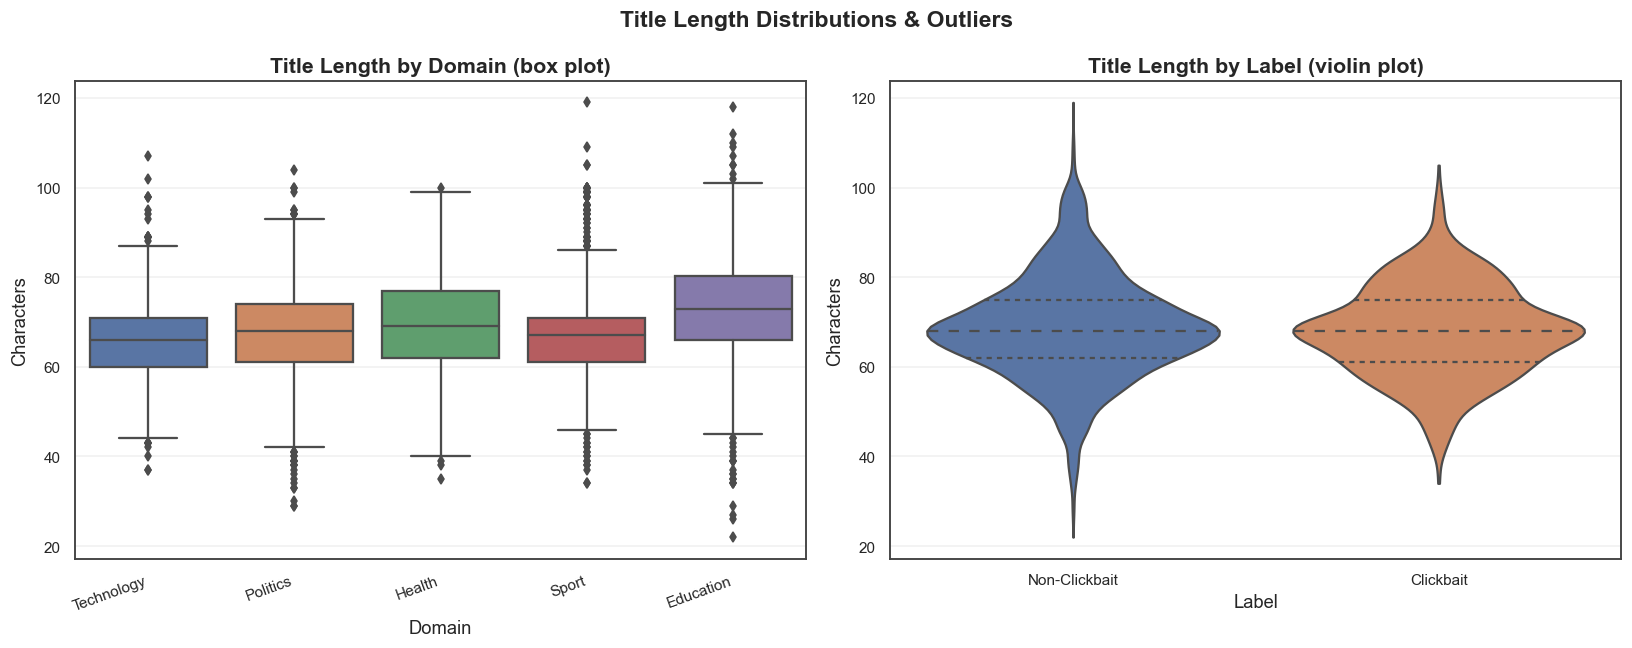

In [33]:
# ---------------- VISUALIZATION: box plots by domain, violin by label ----------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Box plot of character length by domain (outliers visible as points)
sns.boxplot(data=all_df, x="Domain", y="char_len", order=DOMAINS,
            palette=DOMAIN_COLORS, ax=axes[0])
axes[0].set_title("Title Length by Domain (box plot)")
axes[0].set_xlabel("Domain"); axes[0].set_ylabel("Characters")
axes[0].set_xticklabels(DOMAINS, rotation=20, ha="right")

# Violin plot of character length by label (distribution shape + spread)
sns.violinplot(data=all_df, x="Label_Name", y="char_len", order=LABEL_ORDER,
               palette=LABEL_COLORS, cut=0, inner="quartile", ax=axes[1])
axes[1].set_title("Title Length by Label (violin plot)")
axes[1].set_xlabel("Label"); axes[1].set_ylabel("Characters")

fig.suptitle("Title Length Distributions & Outliers", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

# # ---------------- VISUALIZATION: word length by domain split by label ----------------
# fig, ax = plt.subplots(figsize=(13, 6))
# sns.boxplot(data=all_df, x="Domain", y="word_len", hue="Label_Name",
#             order=DOMAINS, hue_order=LABEL_ORDER, palette=LABEL_COLORS, ax=ax)
# ax.set_title("Title Word Count by Domain and Label (box plot)")
# ax.set_xlabel("Domain"); ax.set_ylabel("Words")
# ax.set_xticklabels(DOMAINS, rotation=20, ha="right")
# ax.legend(title="Label", frameon=False)
# plt.tight_layout()
# plt.show()

### 5.12 Title Length Statistics

==========Title Statistics==========


,Domain,Mean_Characters,Median_Characters,Min_Characters,Max_Characters,Std_Characters,Mean_Words,Median_Words,Min_Words,Max_Words,Std_Words
0,Education,72.87,73.0,22,118,12.46,11.11,11.0,4,18,2.15
1,Health,69.27,69.0,35,100,10.71,10.52,10.5,5,16,1.80
2,Politics,67.25,68.0,29,104,11.04,10.03,10.0,4,16,1.84
3,Sport,67.59,67.0,34,119,11.45,10.73,10.0,5,19,1.94
4,Technology,65.53,66.0,37,107,9.28,9.94,10.0,5,17,1.69


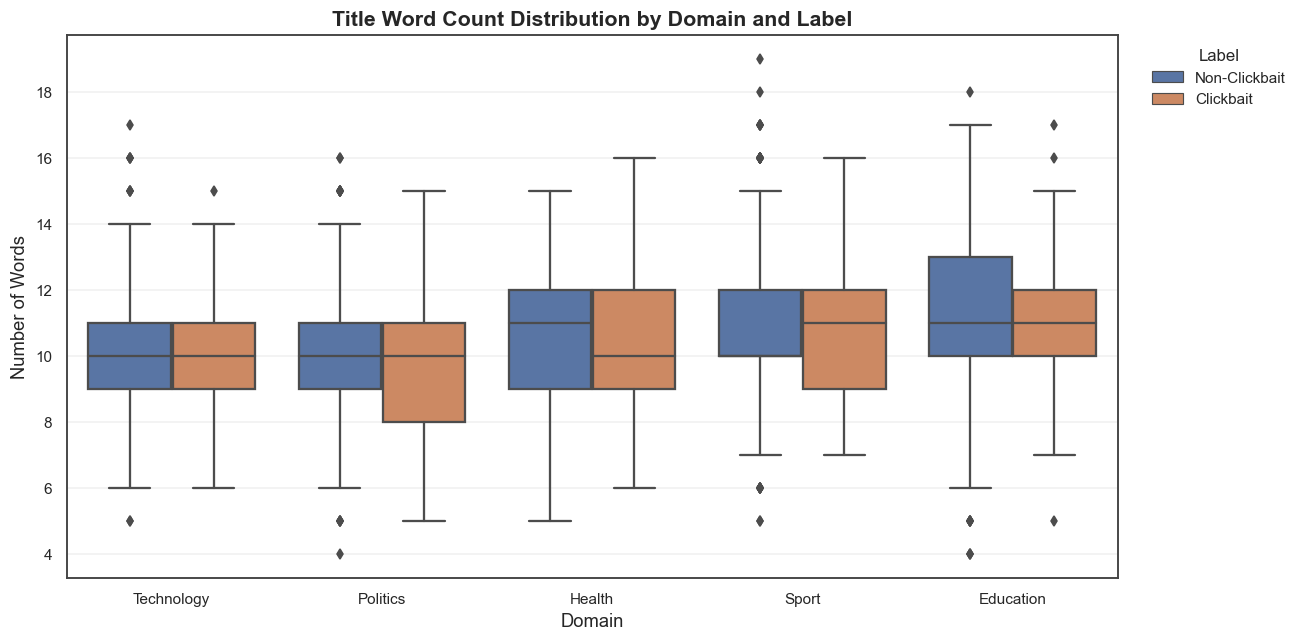

In [34]:
title_data = []

print("==========Title Statistics==========")

for category, df in datasets.items():
    if 'title' not in df.columns:
        continue

    # Exclude missing titles
    valid_df = df.dropna(subset=['title']).copy()

    for _, row in valid_df.iterrows():
        title = str(row['title'])

        title_data.append({
            'Domain': category,
            'Label': row['Label'] if 'Label' in valid_df.columns else None,
            'Title_Length': len(title),
            'Word_Count': len(title.split())
        })

title_df = pd.DataFrame(title_data)

# ===============STATISTICS===============
stats_df = (
    title_df
    .groupby('Domain')
    .agg(
        Mean_Characters=('Title_Length', 'mean'),
        Median_Characters=('Title_Length', 'median'),
        Min_Characters=('Title_Length', 'min'),
        Max_Characters=('Title_Length', 'max'),
        Std_Characters=('Title_Length', 'std'),

        Mean_Words=('Word_Count', 'mean'),
        Median_Words=('Word_Count', 'median'),
        Min_Words=('Word_Count', 'min'),
        Max_Words=('Word_Count', 'max'),
        Std_Words=('Word_Count', 'std')
    )
    .round(2)
    .reset_index()
)

display(stats_df)


# ===============PLOT: WORD COUNT===============
plt.figure(figsize=(12, 6))

ax = sns.boxplot(
    data=title_df,
    x='Domain',
    y='Word_Count',
    hue='Label',
    width=0.8,
    palette=LABEL_COLORS_NUM
)

plt.title('Title Word Count Distribution by Domain and Label')
plt.xlabel('Domain')
plt.ylabel('Number of Words')

handles, _ = ax.get_legend_handles_labels()

ax.legend(
    handles,
    LABEL_ORDER,
    title='Label',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=False
)

plt.tight_layout()
plt.show()

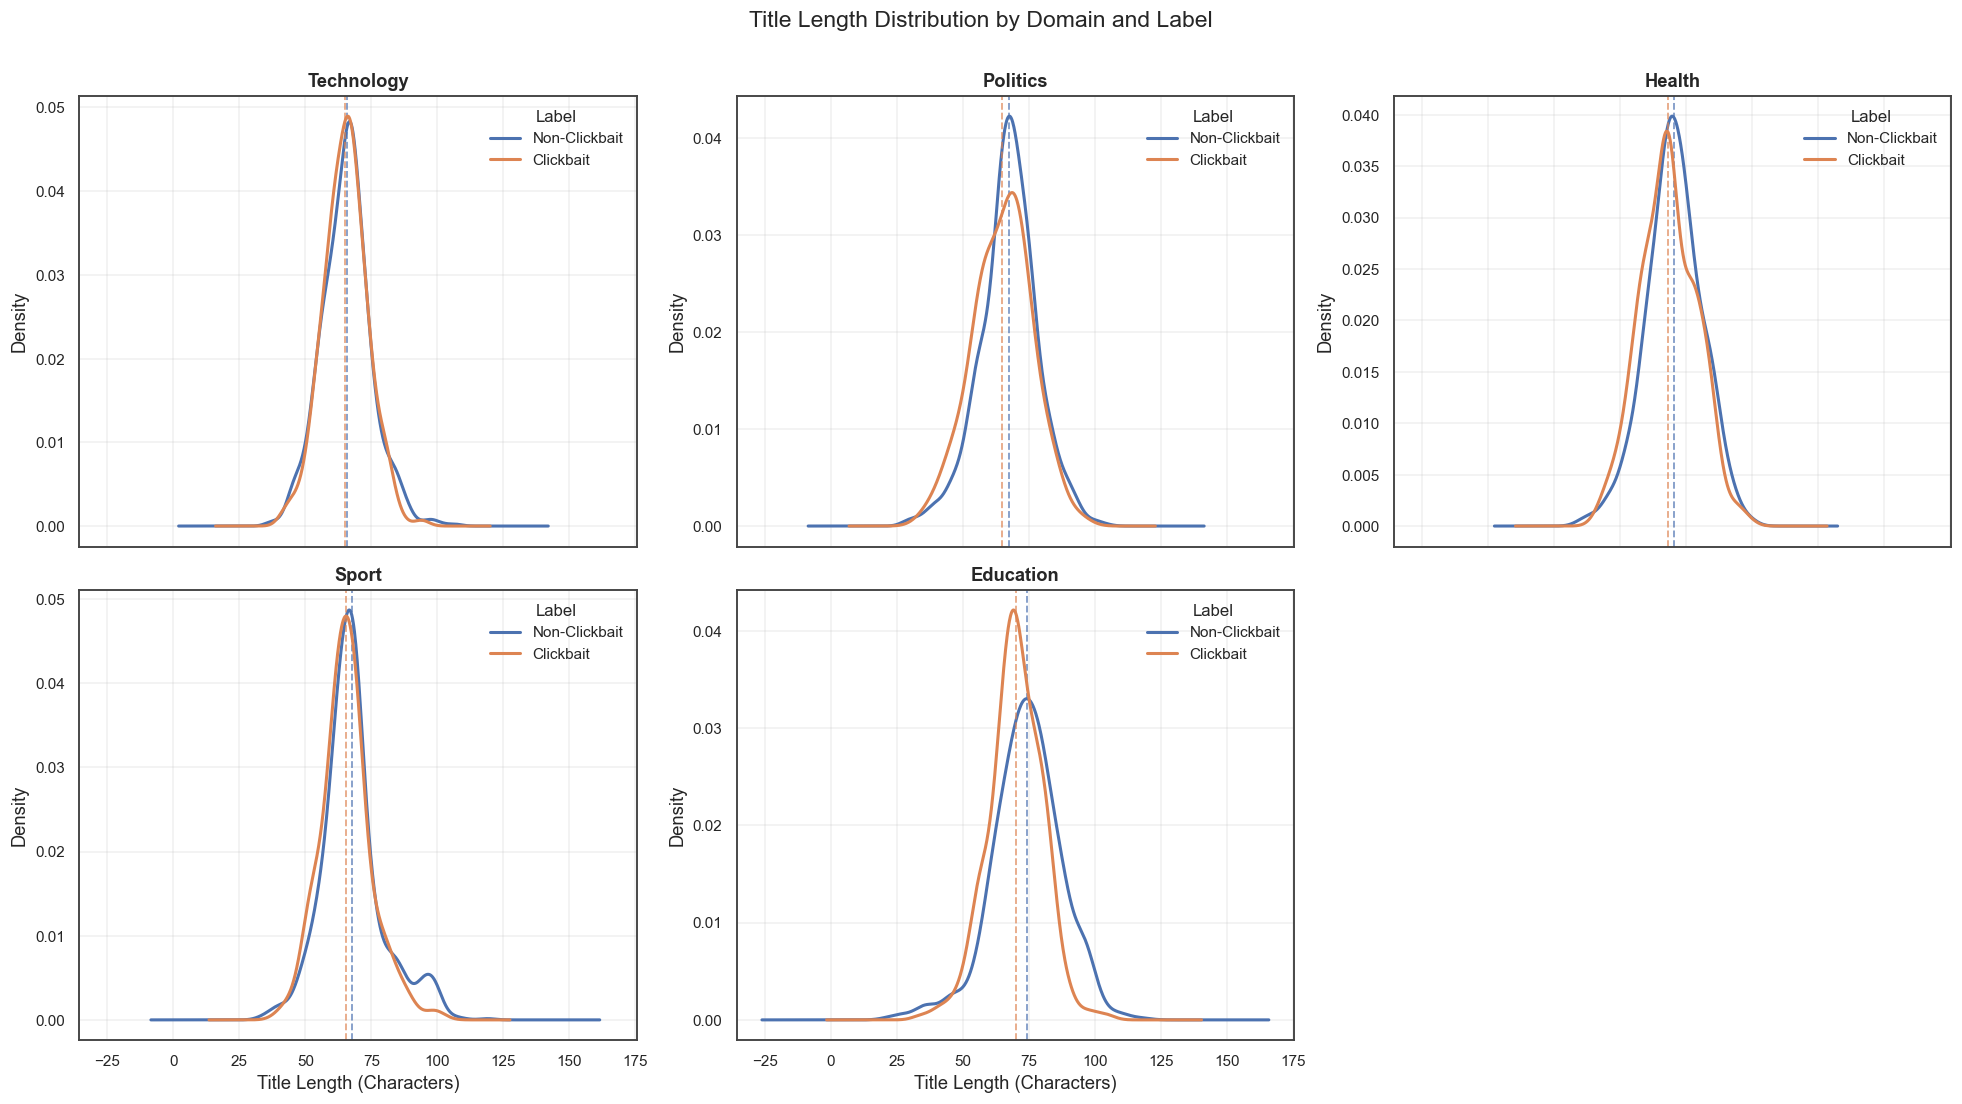

In [35]:
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(18,10),
    sharex=True,
    sharey=False
)

axes = axes.flatten()

for ax, domain in zip(axes, DOMAINS):
    domain_df = title_df[title_df['Domain'] == domain]

    for label, color in LABEL_COLORS_NUM.items():
        subset = domain_df[
            domain_df['Label'] == label
        ]['Title_Length'].dropna()

        if len(subset) < 2:
            continue

        subset.plot.kde(
            ax=ax,
            color=color,
            label=LABEL_NAMES[label],
            linewidth=2
        )

        ax.axvline(
            subset.mean(),
            color=color,
            linestyle='--',
            linewidth=1.2,
            alpha=0.7
        )

    ax.set_title(domain, fontsize=12)
    ax.set_xlabel('Title Length (Characters)')
    ax.set_ylabel('Density')
    ax.legend(title='Label', frameon=False)

# Hide the unused sixth subplot
for ax in axes[len(DOMAINS):]:
    ax.set_visible(False)

fig.suptitle(
    'Title Length Distribution by Domain and Label',
    fontsize=15,
    y=1.002
)

plt.tight_layout()
plt.show()

### 5.13 Special Characters & Stopwords by Label 

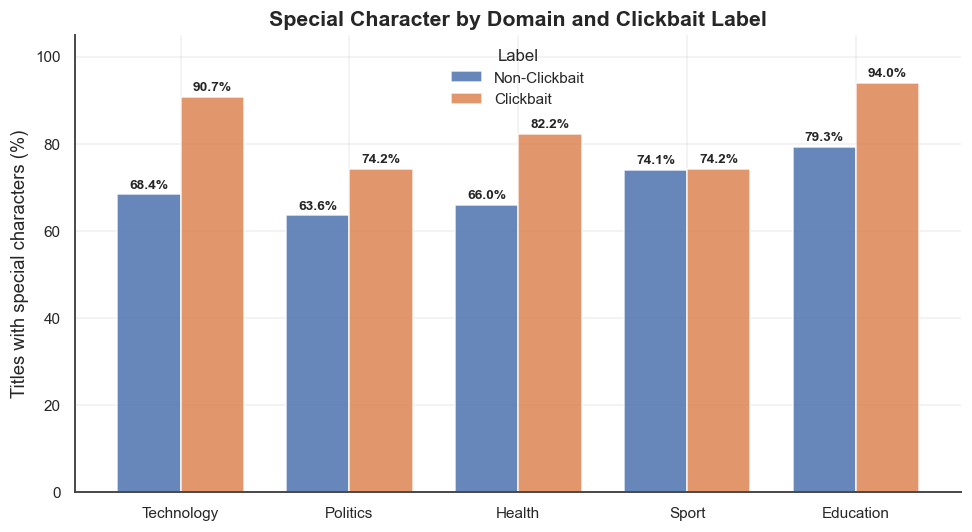

In [36]:
# -- GRAPH 10.1: Special Characters by Label Across Domains --

import pandas as pd
import matplotlib.pyplot as plt

SPECIAL_CHAR_PATTERN = r"[^0-9A-Za-z\s]" 
LABELS = [0, 1]

rows = []
for domain in DOMAINS:
    df = datasets[domain]
    has_special = df["title"].astype(str).str.contains(SPECIAL_CHAR_PATTERN)
    for label in LABELS:
        rows.append({
            "Domain": domain,
            "Label": LABEL_NAMES[label],
            "Pct": has_special[df["Label"] == label].mean() * 100,
        })

pivot = (
    pd.DataFrame(rows)
    .pivot(index="Domain", columns="Label", values="Pct")
    .reindex(index=DOMAINS, columns=[LABEL_NAMES[l] for l in LABELS])
)

ax = pivot.plot.bar(figsize=(9, 5), color=[LABEL_COLORS_NUM[c] for c in plot_df.columns], width=0.75, edgecolor="white", alpha=0.85)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, fontweight="bold", padding=2)

ax.set_ylim(0, 105)
ax.set_xlabel("")
ax.set_ylabel("Titles with special characters (%)")
ax.set_title(
    "Special Character by Domain and Clickbait Label",
    fontsize=14,
    fontweight="bold",
)
ax.legend(title="Label", frameon=False)
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

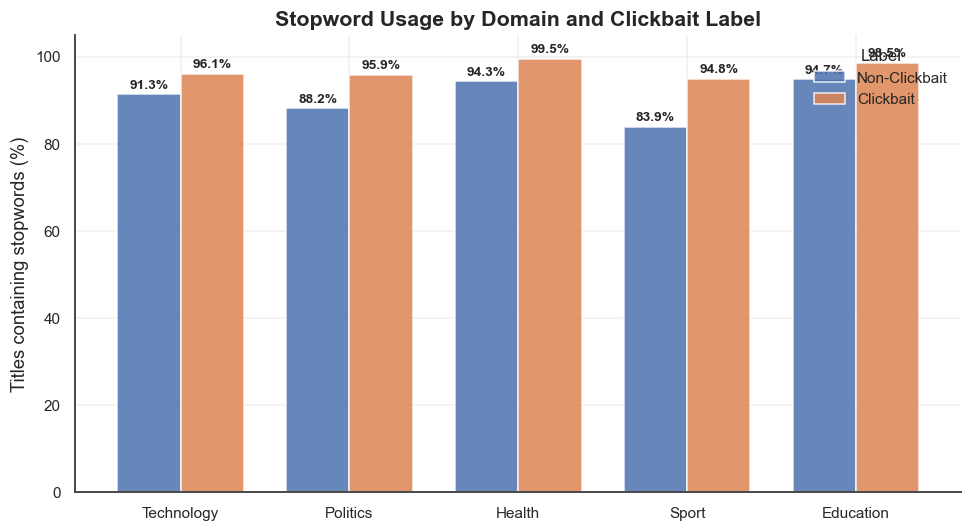

In [37]:
# -- GRAPH 10.2: % of Titles Containing Stopwords by Domain and Label --

import re
import pandas as pd
import matplotlib.pyplot as plt
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

STOPWORDS = set(StopWordRemoverFactory().get_stop_words())
COLORS = ["#E07A5F", "#81B29A"]
LABELS = [0, 1]


def has_stopword(text):
    return any(w in STOPWORDS for w in re.findall(r"[a-z]+", str(text).lower()))


rows = []
for domain in DOMAINS:
    df = datasets[domain]
    has_sw = df["title"].apply(has_stopword)
    for label in LABELS:
        rows.append({
            "Domain": domain,
            "Label": LABEL_NAMES[label],
            "Pct": has_sw[df["Label"] == label].mean() * 100,
        })

pivot = (
    pd.DataFrame(rows)
    .pivot(index="Domain", columns="Label", values="Pct")
    .reindex(index=DOMAINS, columns=[LABEL_NAMES[l] for l in LABELS])
)

ax = pivot.plot.bar(figsize=(9, 5), color=[LABEL_COLORS_NUM[c] for c in plot_df.columns], width=0.75, edgecolor="white", alpha=0.85)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=9, fontweight="bold", padding=2)

ax.set_ylim(0, 105)
ax.set_xlabel("")
ax.set_ylabel("Titles containing stopwords (%)")
ax.set_title(
    "Stopword Usage by Domain and Clickbait Label",
    fontsize=14,
    fontweight="bold",
)
ax.legend(title="Label", frameon=False)
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## 6. Summary and Conclusions

In [38]:
print("EXPLORATORY DATA ANALYSIS SUMMARY")

total_articles = sum(len(df) for df in datasets.values())
print(f"\nTotal Articles Analyzed: {total_articles:,}")
print(f"Number of Categories: {len(datasets)}")
print(f"Categories: {', '.join(datasets.keys())}")

print("\nKey Findings:")
for category, df in datasets.items():
    print(f"\n{category}:")
    print(f"  - Articles: {len(df):,}")
    if 'source' in df.columns:
        print(f"  - Sources: {df['source'].nunique()}")
    if 'Label' in df.columns:
        label_counts = df['Label'].value_counts()
        if len(label_counts) == 2:
            ratio = label_counts.max() / label_counts.min()
            print(f"  - Class Balance: {ratio:.2f}:1 ({'Balanced' if ratio < 1.5 else 'Imbalanced'})")
    if 'title' in df.columns:
        avg_length = df['title'].astype(str).str.len().mean()
        print(f"  - Avg Title Length: {avg_length:.0f} characters")

EXPLORATORY DATA ANALYSIS SUMMARY

Total Articles Analyzed: 5,000
Number of Categories: 5
Categories: Technology, Politics, Health, Sport, Education

Key Findings:

Technology:
  - Articles: 1,000
  - Sources: 4
  - Class Balance: 3.88:1 (Imbalanced)
  - Avg Title Length: 66 characters

Politics:
  - Articles: 1,000
  - Sources: 3
  - Class Balance: 9.31:1 (Imbalanced)
  - Avg Title Length: 67 characters

Health:
  - Articles: 1,000
  - Sources: 4
  - Class Balance: 1.28:1 (Balanced)
  - Avg Title Length: 69 characters

Sport:
  - Articles: 1,000
  - Sources: 4
  - Class Balance: 9.31:1 (Imbalanced)
  - Avg Title Length: 68 characters

Education:
  - Articles: 1,000
  - Sources: 4
  - Class Balance: 1.99:1 (Imbalanced)
  - Avg Title Length: 73 characters
